# Q1E | Train Polynomial Regression

# Imports

In [1]:
from itertools import product

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (needed before importing IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from OLD.Q1.consts import TRAIN_PATH, COLUMNS, TARGET, ALPHAS, LEARNING_RATES, MODEL_OUTPUT_DIR

from OLD.Q1.utils import cv_fold_scores
from OLD.utils.scoring.standard_error import standard_error

# Fetch Data

In [2]:
train_df = pd.read_csv(TRAIN_PATH)

X = train_df.drop(columns=[TARGET])
print(X.shape)
y = train_df[TARGET]
print(y.shape)

FEATURES = [val['col'] for key, val in COLUMNS.items() if key != 'LL']
FOLDS = cross_validation.make_folds(
	data=train_df,
	feature_columns=FEATURES
)
print(len(FOLDS))

(1559, 8)
(1559,)
20


# Method
**Polynomial regression.** Polynomial regression is linear regression fit on extra columns. `PolynomialFeatures(degree)` takes the 8 raw columns and adds every product of up to `degree` of them. At degree 2 that is each column squared and each pair of columns multiplied together. The model fit on those columns is the same as in Q1D: closed form `LinearRegression` first, then `SGDRegressor` with no penalty, Ridge, Lasso and Elastic Net. Degree 1 adds no columns, so it is the Q1D model on the 8 raw columns. Q1E starts again from the 8 raw columns: the polynomial terms take the place of the hand-made shapes from Q1D.

**Pipeline.** Every model uses the same four steps: `StandardScaler`, `PolynomialFeatures`, `StandardScaler`, model. The first scaler centers each raw column before it is squared or multiplied. The second puts all the polynomial columns on one scale. The SGD section tests the pipeline without the first scaler.

**Cross-validation.** Every model is scored with 4-fold cross-validation, repeated with 5 different seeds for the shuffle, which gives 20 folds. The folds are built once (`FOLDS`) and reused by every experiment, so every model is validated on exactly the same rows and any two models can be compared fold by fold. Rows with a missing value are never used for validation. They are dropped from training too, except in the Missing Rows section, which tests imputing them.

**Metric.** The metric is RMSE (root mean squared error), reported for the validation rows and for the training rows of each fold. It is in the same units as Life Ladder, it penalizes large misses more than small ones, and it matches the squared error that linear regression minimizes.

**Noise rule.** A lower mean RMSE is not automatically a real improvement, because the score moves from fold to fold. Each experiment is compared with a baseline through the 20 per-fold differences in validation RMSE (experiment minus baseline). SE is the standard error of the mean of those differences, corrected for the folds sharing most of their training rows. The rule used throughout:

- **really better:** the mean change is below -1 SE.
- **really worse:** the mean change is above +1 SE.
- **noise:** anything in between. The simpler model is kept.

**Charts.** Each experiment has one chart. Left: RMSE on every fold, dots for validation and x marks for training, with the means in the legend. Right: the per-fold change in validation RMSE against the baseline (green is better, red is worse), the mean change as a dashed line, and the ±1 SE noise band in gray. The title gives the verdict.

# Closed Form by Degree
This section changes one thing, the degree, and fits every degree with closed form `LinearRegression`: one direct solve, with no learning rate and no penalty to tune. scikit-learn computes that solution with an SVD-based solver. Rows with a missing value are dropped.

## Closed Form by Degree > Degree 1
The baseline. Degree 1 adds no columns, so this is the Q1D closed form model on the 8 raw columns.

In [3]:
degree_scores = {}
degree_scores[1] = cross_validation.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=make_pipeline(
		StandardScaler(),
		PolynomialFeatures(degree=1, include_bias=False),
		StandardScaler(),
		LinearRegression(),
	),
	folds=FOLDS
)

degree1_val_scores, degree1_train_scores = degree_scores[1]
print(f"val RMSE {degree1_val_scores.mean():.4f} | train RMSE {degree1_train_scores.mean():.4f}")

val RMSE 0.5458 | train RMSE 0.5414


## Closed Form by Degree > Degree 2
Degree 2 adds each column squared and each pair of columns multiplied together.

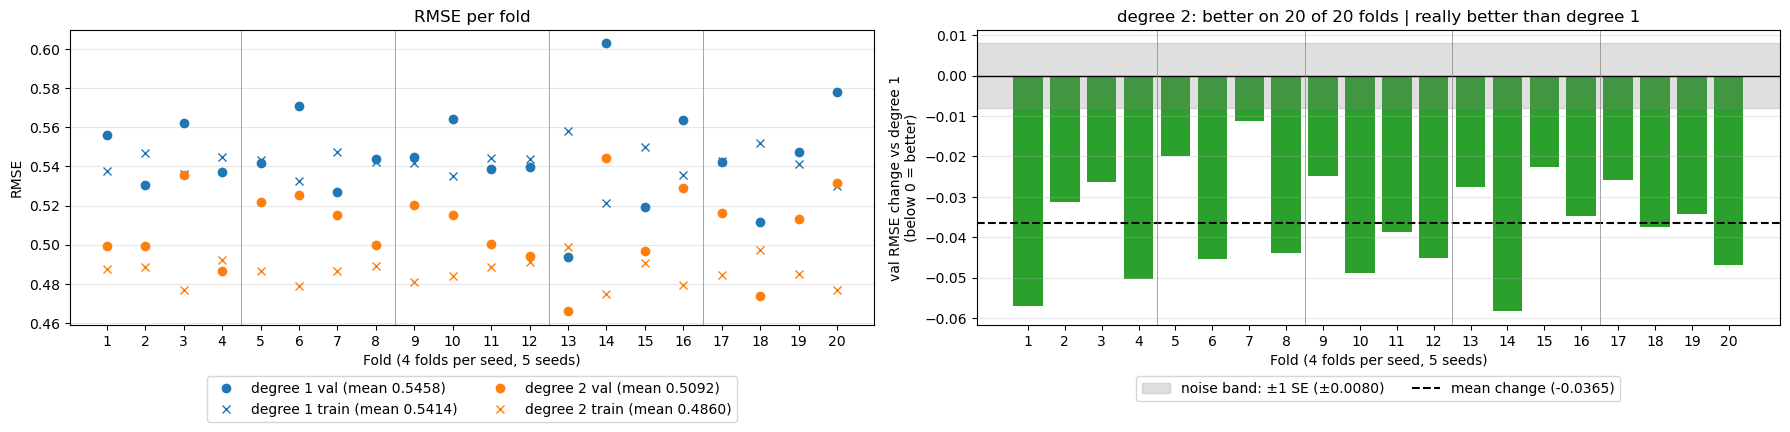

In [4]:
degree_scores[2] = cross_validation.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=make_pipeline(
		StandardScaler(),
		PolynomialFeatures(degree=2, include_bias=False),
		StandardScaler(),
		LinearRegression(),
	),
	folds=FOLDS
)

cv_fold_scores(
	baseline=degree_scores[1],
	compare=degree_scores[2],
	baseline_name="degree 1",
	compare_name="degree 2",
)

## Closed Form by Degree > Degrees 3 and 4
Each is compared with degree 2.

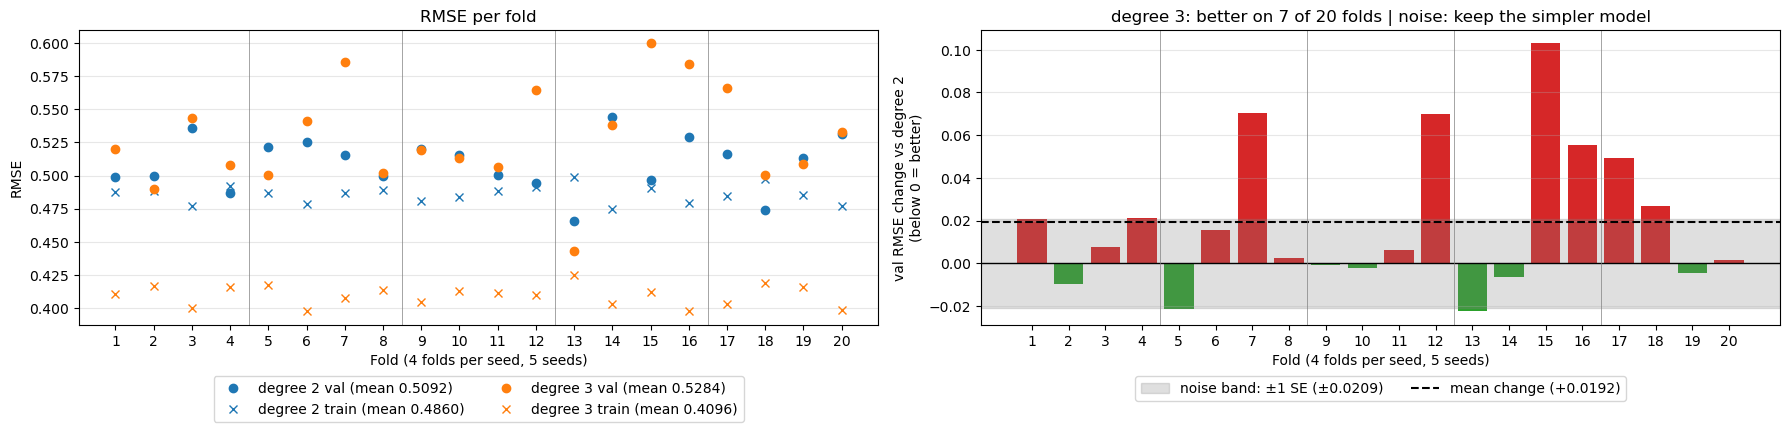

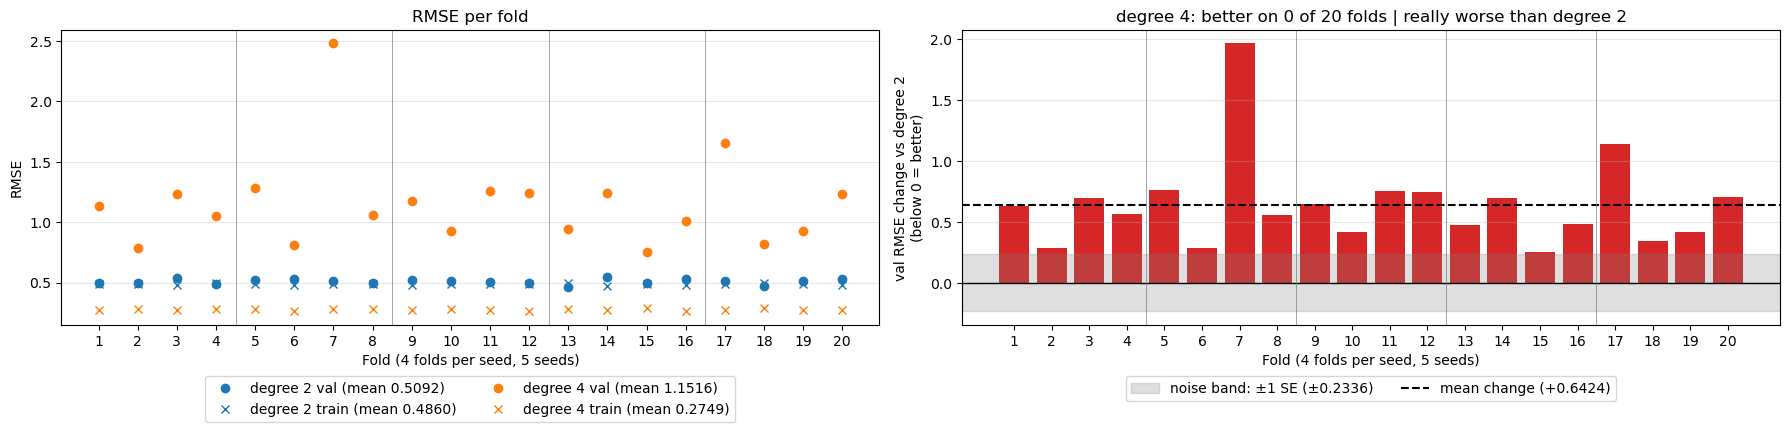

In [5]:
for degree in [3, 4]:
	degree_scores[degree] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=degree, include_bias=False),
			StandardScaler(),
			LinearRegression(),
		),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=degree_scores[2],
		compare=degree_scores[degree],
		baseline_name="degree 2",
		compare_name=f"degree {degree}",
	)

## Degree Summary

In [6]:
degree_summary = pd.DataFrame({
	f"degree {degree}": {
		# number of columns PolynomialFeatures makes from the 8 raw columns
		"columns": PolynomialFeatures(degree=degree, include_bias=False).fit(train_df[FEATURES].dropna()).n_output_features_,
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs degree 1": (val - degree1_val_scores).mean(),
		"SE": standard_error(diff=val - degree1_val_scores),
		"folds better": np.sum(val < degree1_val_scores),
	}
	for degree, (val, train) in degree_scores.items()
}).T
degree_summary[["columns", "folds better"]] = degree_summary[["columns", "folds better"]].astype(int)
degree_summary["change vs degree 1"] = degree_summary["change vs degree 1"].map(np.format_float_positional)
degree_summary

,columns,val RMSE,train RMSE,change vs degree 1,SE,folds better
degree 1,8,0.545777,0.541366,0.,0.000000,0
degree 2,44,0.509237,0.485974,-0.03654036748145153,0.007961,20
degree 3,164,0.528389,0.409553,-0.017388318596895193,0.024057,15
degree 4,494,1.151620,0.274907,0.6058423830354822,0.236926,0


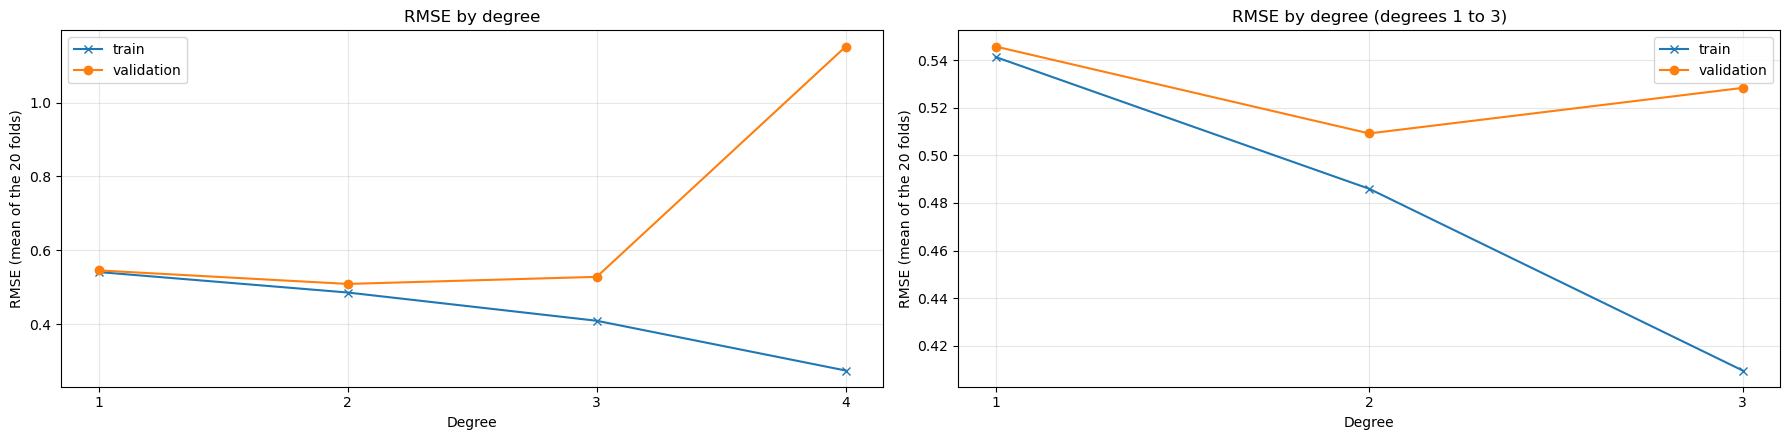

In [7]:
degrees = list(degree_scores)
val_means = [degree_scores[degree][0].mean() for degree in degrees]
train_means = [degree_scores[degree][1].mean() for degree in degrees]

fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(18, 4.5))

# left: every degree. right: degrees 1 to 3, where the two lines can be told apart
for ax, n_degrees, title in [
	(ax_all, 4, "RMSE by degree"),
	(ax_zoom, 3, "RMSE by degree (degrees 1 to 3)"),
]:
	ax.plot(degrees[:n_degrees], train_means[:n_degrees], "x-", color="C0", label="train")
	ax.plot(degrees[:n_degrees], val_means[:n_degrees], "o-", color="C1", label="validation")
	ax.set_xticks(degrees[:n_degrees])
	ax.set_xlabel("Degree")
	ax.set_ylabel("RMSE (mean of the 20 folds)")
	ax.set_title(title)
	ax.grid(alpha=0.3)
	ax.legend()

plt.tight_layout()
plt.show()

**Impact of the degree.** Degree 2 is the only step that is a real improvement. It lowers validation RMSE from 0.5458 at degree 1 to 0.5092 (-0.0365, SE 0.0080) and is better on all 20 folds. Degree 3 scores 0.5284. Against degree 2 that is a change of +0.0192, inside the ±0.0209 noise band, and it is better on only 7 of 20 folds, so the verdict is noise and the simpler degree 2 is kept. Against degree 1, degree 3 is inside the noise too (-0.0174, SE 0.0241). Degree 4 scores 1.1516. It is really worse than degree 2 (+0.6424, SE 0.2336, better on 0 of 20 folds) and really worse than degree 1 (+0.6058, SE 0.2369).

**Underfitting and overfitting.** Training RMSE falls at every degree (0.5414, 0.4860, 0.4096, 0.2749) as the number of columns grows (8, 44, 164, 494). Validation RMSE falls once and then rises (0.5458, 0.5092, 0.5284, 1.1516). Degree 1 underfits: its training and validation RMSE are close together (0.5414 and 0.5458) and both are higher than at degree 2, so the degree 2 columns improve the fit on rows the model has not seen. From degree 3 on the model overfits: training RMSE keeps improving while validation RMSE gets worse. At degree 4 the model fits its training rows at 0.2749 and misses the validation rows at 1.1516, and one fold reaches about 2.5.

Degree 2 is used in every section below (`BEST_DEGREE = 2`).

## Selected Degree
The degree every section below uses. It is typed by hand from the Degree Summary.

In [8]:
BEST_DEGREE = 2

# Missing Rows
Every run so far dropped the rows with a missing value from training. This section keeps them and fills in the missing values with an imputer, placed first in the pipeline. Every run uses closed form `LinearRegression` at degree `BEST_DEGREE` and is compared with dropping the incomplete rows. The validation rows do not change: they are complete rows only.

In [9]:
complete_rows = train_df[FEATURES].notna().all(axis=1)
print(f"complete rows: {complete_rows.sum()} | incomplete rows: {(~complete_rows).sum()}")

# the baseline of this section: closed form at BEST_DEGREE with the incomplete rows dropped
drop_val_scores, drop_train_scores = degree_scores[BEST_DEGREE]

rows_scores = {}

complete rows: 1374 | incomplete rows: 185


## Missing Rows > Median Imputer
Each missing value is filled with the median of its column.

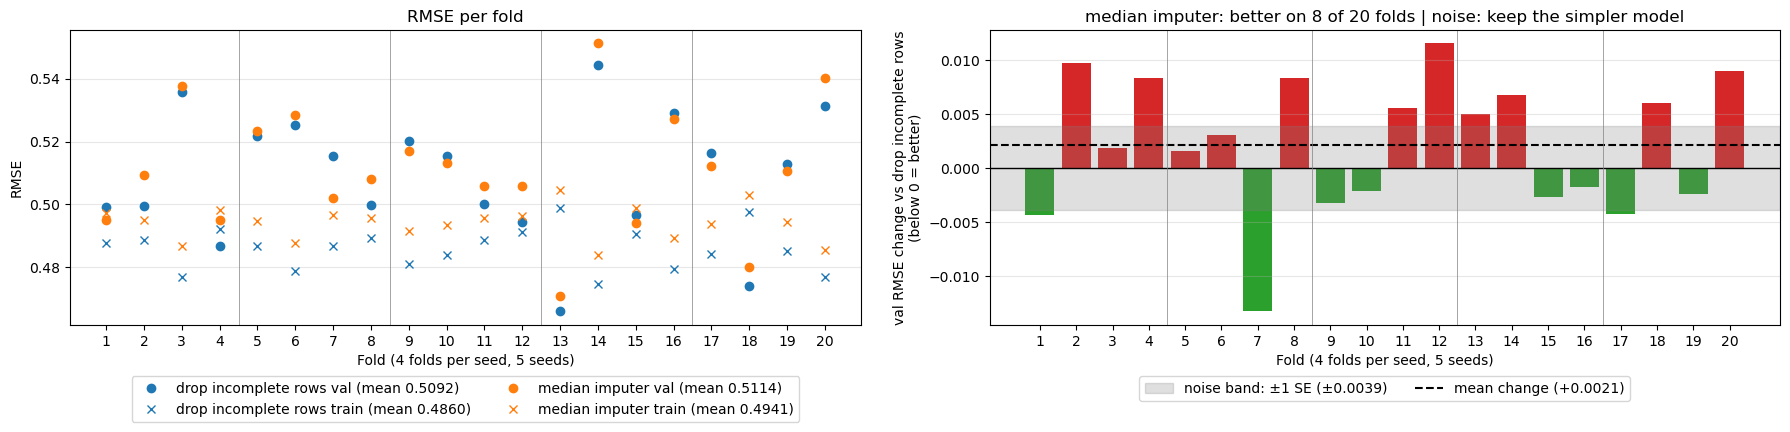

In [10]:
rows_scores["median"] = cross_validation.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=make_pipeline(
		SimpleImputer(strategy="median"),
		StandardScaler(),
		PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
		StandardScaler(),
		LinearRegression(),
	),
	folds=FOLDS,
	drop_incomplete=False
)

cv_fold_scores(
	baseline=(drop_val_scores, drop_train_scores),
	compare=rows_scores["median"],
	baseline_name="drop incomplete rows",
	compare_name="median imputer",
)

## Missing Rows > Other Imputers
- **median + indicator:** the median imputer, plus one extra 0/1 column per attribute that marks the rows where it was missing. The extra columns go through `PolynomialFeatures` like any other column.
- **KNN:** each missing value is filled from the 5 most similar rows. The columns are scaled first, so that no column dominates the distance.
- **iterative:** each column with missing values is predicted from the other columns.

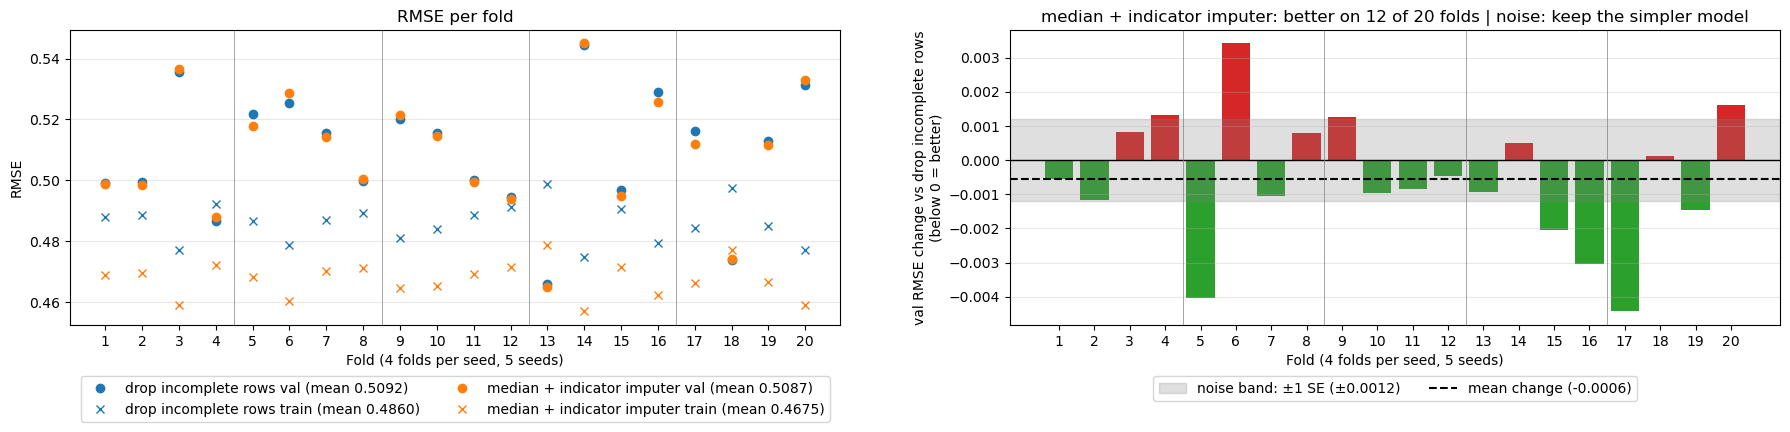

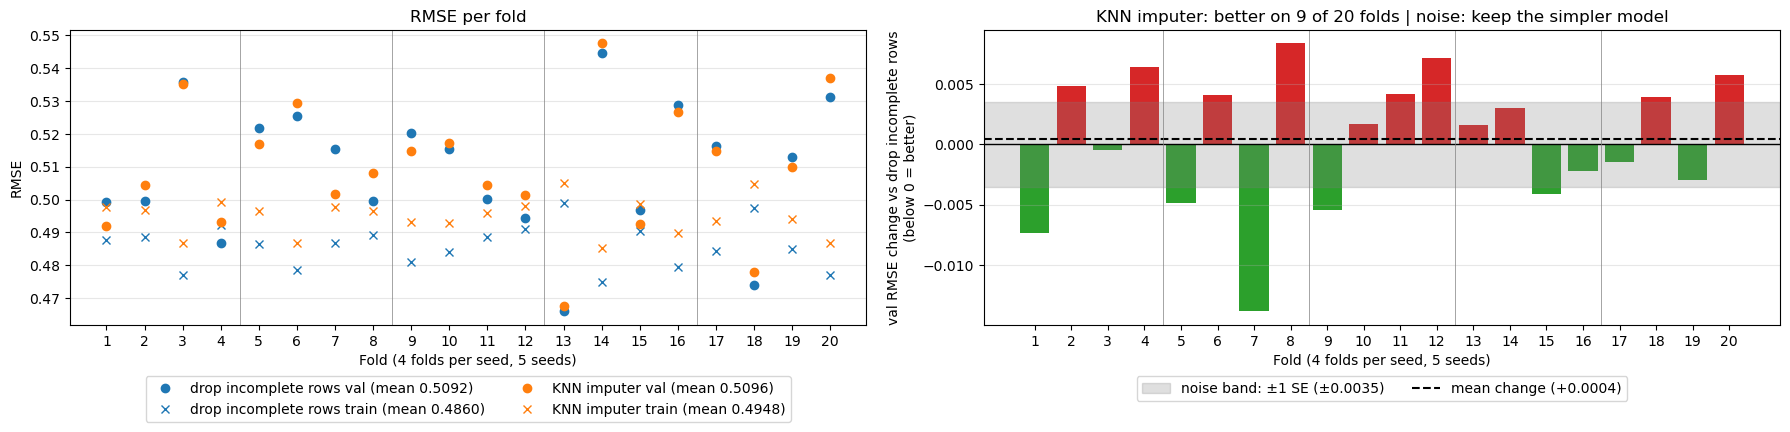

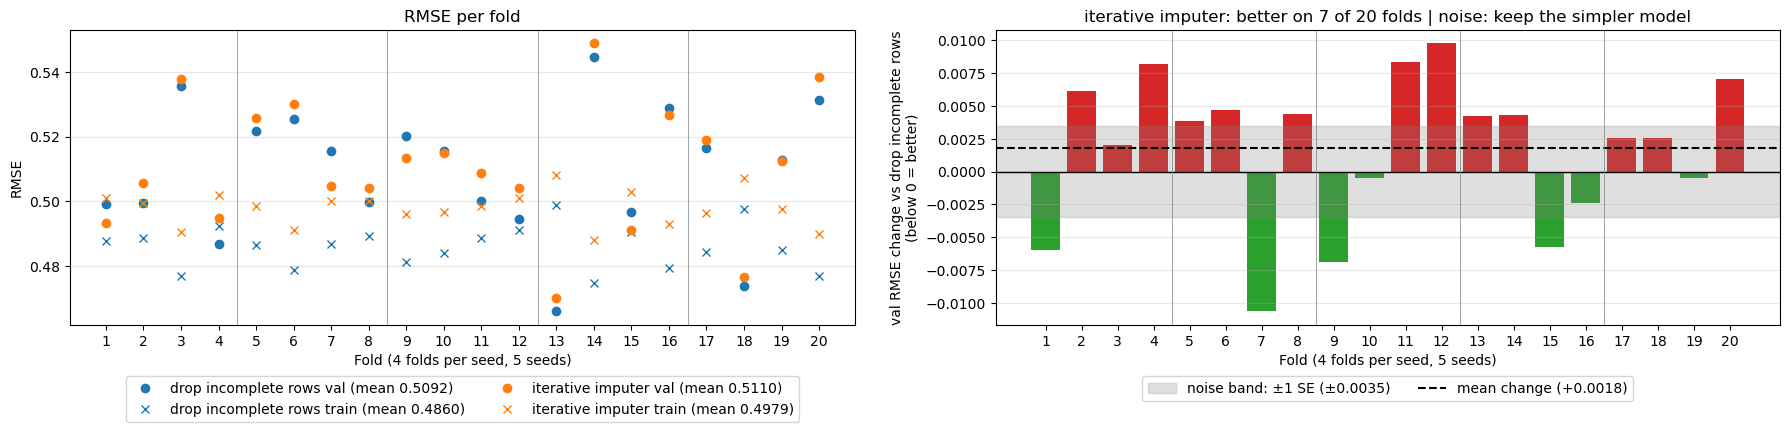

In [11]:
IMPUTERS = {
	"median + indicator": make_pipeline(
		SimpleImputer(strategy="median", add_indicator=True),
		StandardScaler(),
		PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
		StandardScaler(),
		LinearRegression(),
	),
	# KNN needs scaled columns, so the first scaler comes before the imputer (StandardScaler ignores missing values)
	"KNN": make_pipeline(
		StandardScaler(),
		KNNImputer(),
		PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
		StandardScaler(),
		LinearRegression(),
	),
	"iterative": make_pipeline(
		IterativeImputer(random_state=42),
		StandardScaler(),
		PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
		StandardScaler(),
		LinearRegression(),
	),
}

for name, estimator in IMPUTERS.items():
	rows_scores[name] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=estimator,
		folds=FOLDS,
		drop_incomplete=False
	)

	cv_fold_scores(
		baseline=(drop_val_scores, drop_train_scores),
		compare=rows_scores[name],
		baseline_name="drop incomplete rows",
		compare_name=f"{name} imputer",
	)

## Missing Rows Summary

In [12]:
rows_runs = {"drop incomplete rows": (drop_val_scores, drop_train_scores)}
for name, val_train in rows_scores.items():
	rows_runs[f"{name} imputer"] = val_train

rows_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs drop": (val - drop_val_scores).mean(),
		"SE": standard_error(diff=val - drop_val_scores),
		"folds better": np.sum(val < drop_val_scores),
	}
	for name, (val, train) in rows_runs.items()
}).T.sort_values("change vs drop")
rows_summary["folds better"] = rows_summary["folds better"].astype(int)
rows_summary["change vs drop"] = rows_summary["change vs drop"].map(np.format_float_positional)
rows_summary

,val RMSE,train RMSE,change vs drop,SE,folds better
median + indicator imputer,0.508678,0.467452,-0.0005589647861383162,0.001188,12
drop incomplete rows,0.509237,0.485974,0.,0.000000,0
KNN imputer,0.509644,0.494828,0.000406889609545788,0.003506,9
iterative imputer,0.511021,0.497914,0.001783663281301745,0.003485,7
median imputer,0.511369,0.494137,0.002132386882605475,0.003895,8


**Impact of imputing the missing rows.** The training data has 185 incomplete rows next to 1374 complete ones. Keeping them does not help at degree 2. All four imputers are within noise of dropping the incomplete rows (0.5092): each change is smaller than its SE. The median + indicator imputer scores 0.5087 (-0.0006, SE 0.0012, better on 12 of 20 folds), KNN 0.5096 (+0.0004, SE 0.0035), iterative 0.5110 (+0.0018, SE 0.0035) and median 0.5114 (+0.0021, SE 0.0039). Adding the indicator columns to the median imputer lowers training RMSE from 0.4941 to 0.4675, while validation RMSE only moves from 0.5114 to 0.5087: the extra columns fit the training rows more closely without predicting new rows better. By the noise rule the simpler option is kept, so the incomplete rows stay dropped in every section below.

# Stochastic Gradient Descent (SGD)
Every model from here on uses degree `BEST_DEGREE`, with rows that have a missing value dropped. Plain SGD (no penalty) is first compared with closed form at the same degree. Every penalty and learning rate experiment is then compared with plain SGD.

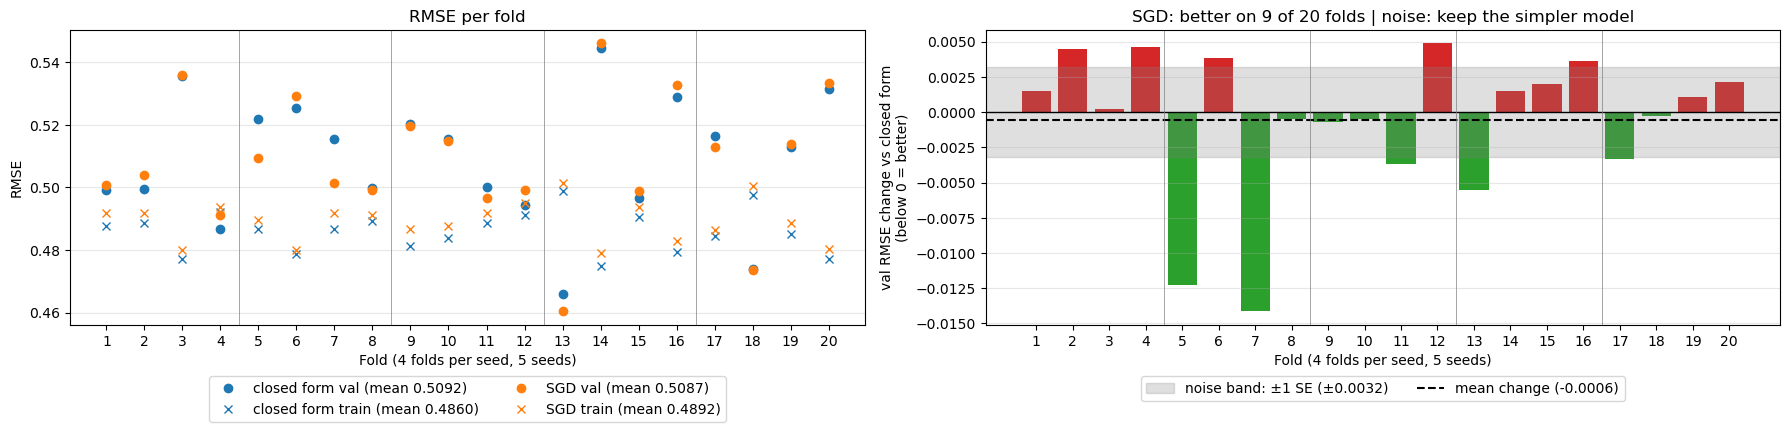

In [13]:
sgd_val_scores, sgd_train_scores = cross_validation.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=make_pipeline(
		StandardScaler(),
		PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
		StandardScaler(),
		SGDRegressor(penalty=None, random_state=42),
	),
	folds=FOLDS
)

cv_fold_scores(
	baseline=degree_scores[BEST_DEGREE],
	compare=(sgd_val_scores, sgd_train_scores),
	baseline_name="closed form",
	compare_name="SGD",
)

**SGD against closed form.** At degree 2, plain SGD (no penalty) scores a validation RMSE of 0.5087 against 0.5092 for closed form. The change of -0.0006 is inside the ±0.0032 noise band and SGD is better on 9 of 20 folds, so the two are a tie. On the training rows SGD stops slightly short of closed form (0.4892 against 0.4860). Plain SGD is the baseline for every experiment below.

## Without the First Scaler
The same plain SGD with the first `StandardScaler` removed, so `PolynomialFeatures` squares and multiplies the raw columns as they are. Compared with plain SGD above.

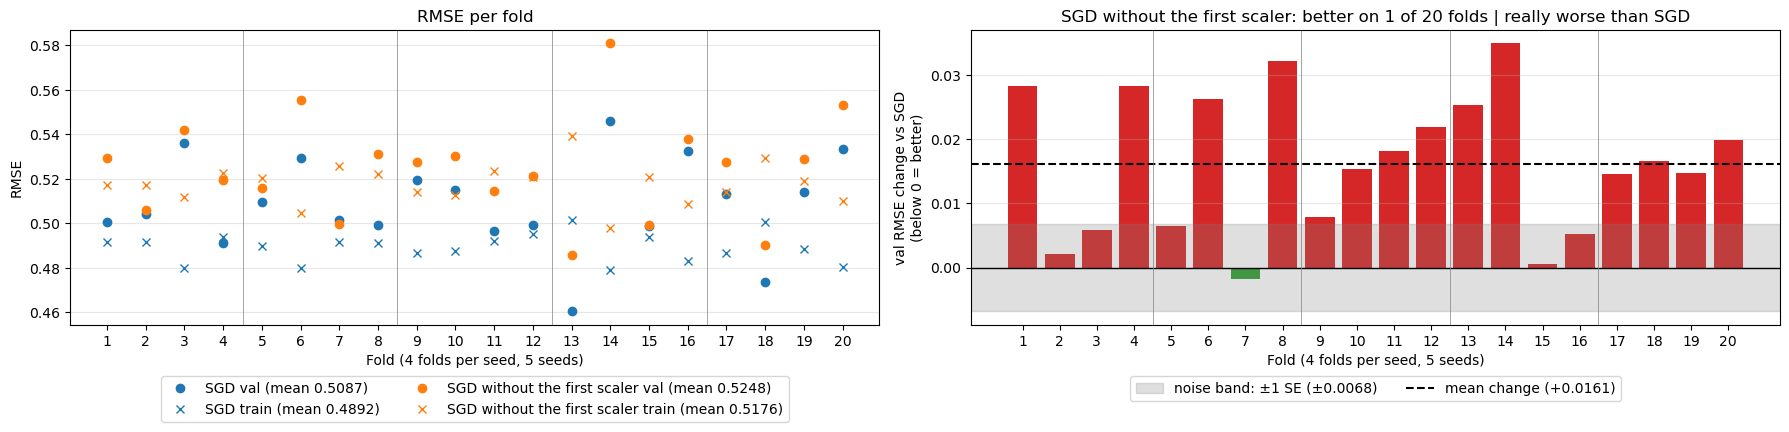

In [14]:
one_scaler_val_scores, one_scaler_train_scores = cross_validation.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=make_pipeline(
		PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
		StandardScaler(),
		SGDRegressor(penalty=None, random_state=42),
	),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(sgd_val_scores, sgd_train_scores),
	compare=(one_scaler_val_scores, one_scaler_train_scores),
	baseline_name="SGD",
	compare_name="SGD without the first scaler",
)

**Impact of the first scaler.** Without the first scaler, plain SGD is really worse: 0.5248 against 0.5087 (+0.0161, SE 0.0068, better on 1 of 20 folds). Its training RMSE is worse too (0.5176 against 0.4892), so this is a poorer fit, not overfitting. Both runs use degree 2 and the same model settings. Only the scaling before `PolynomialFeatures` differs. With the first scaler SGD matches closed form (0.5087 against 0.5092). Without it SGD stops well short of closed form (0.5248). The two-scaler pipeline is kept.

## Lasso

In [15]:
lasso_scores = {}

### Lasso > Penalty

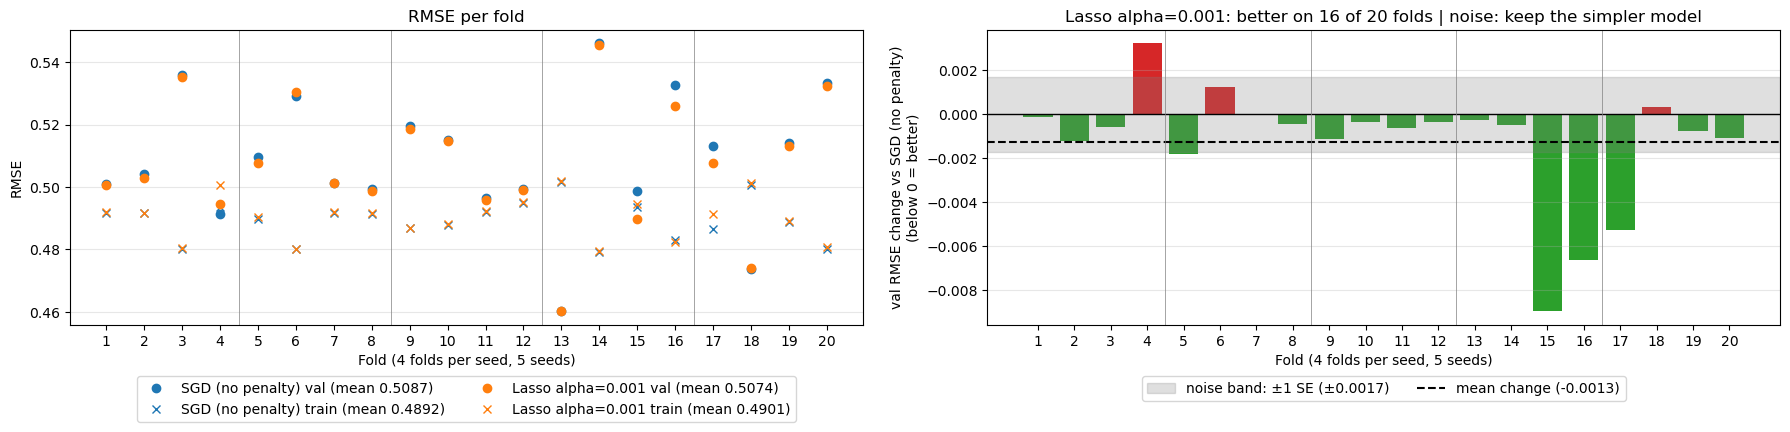

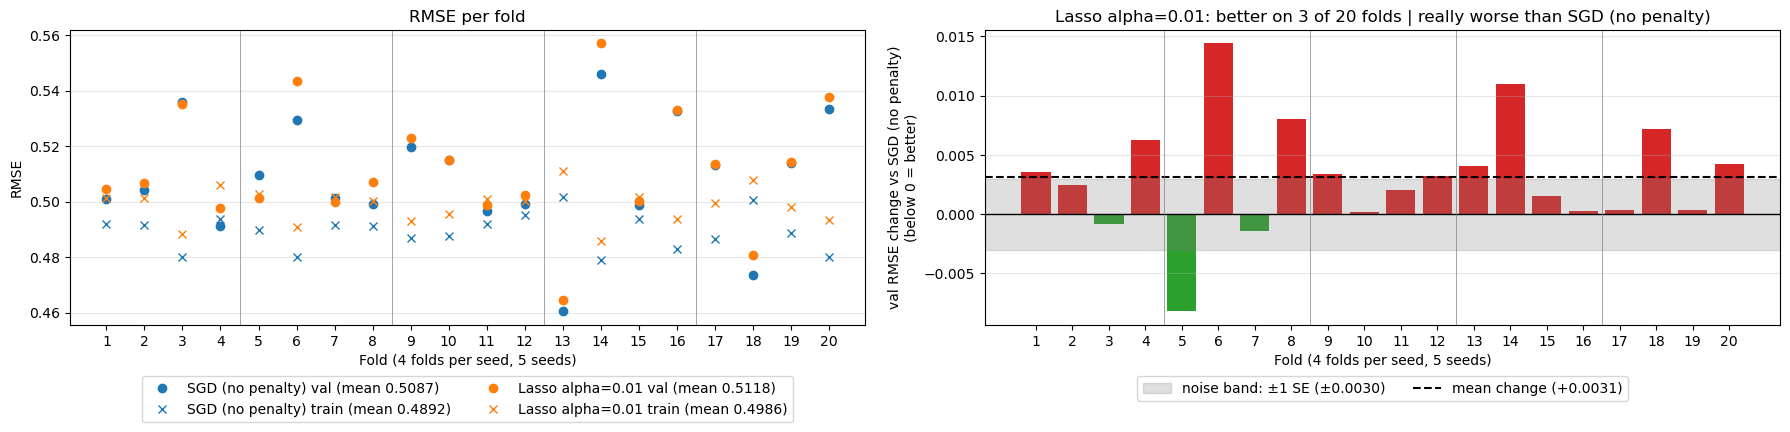

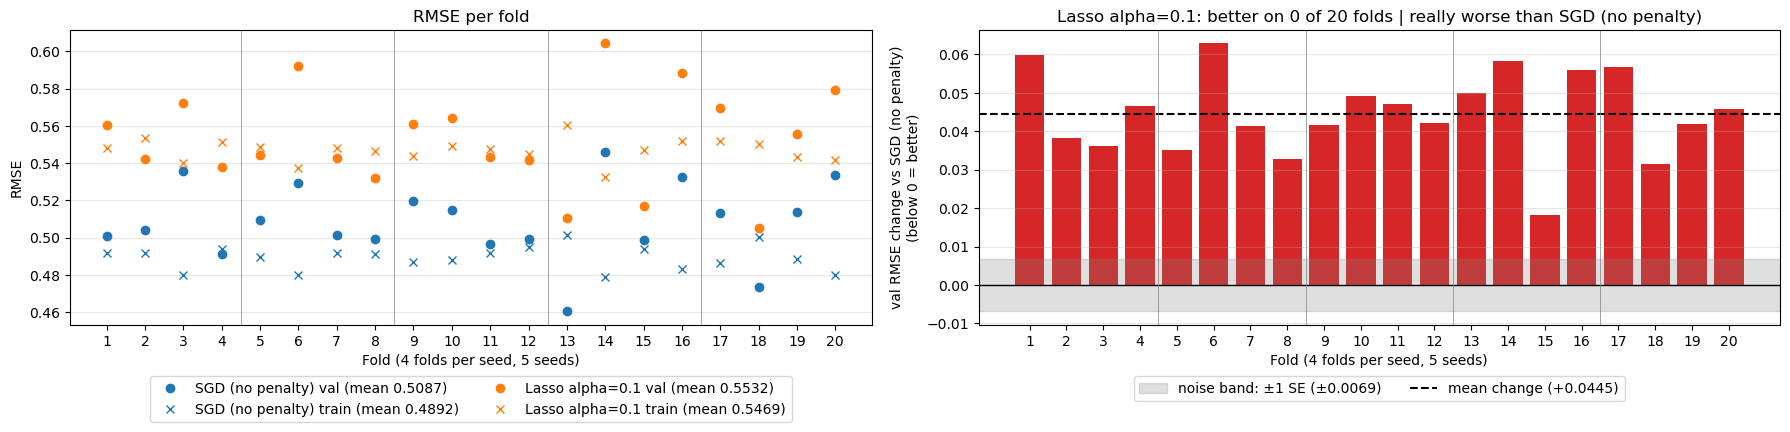

In [16]:
for alpha in ALPHAS:
	lasso_scores[("alpha", alpha)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty='l1', alpha=alpha, random_state=42),
		),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso alpha={alpha}",
	)

### Lasso > Learning Rate

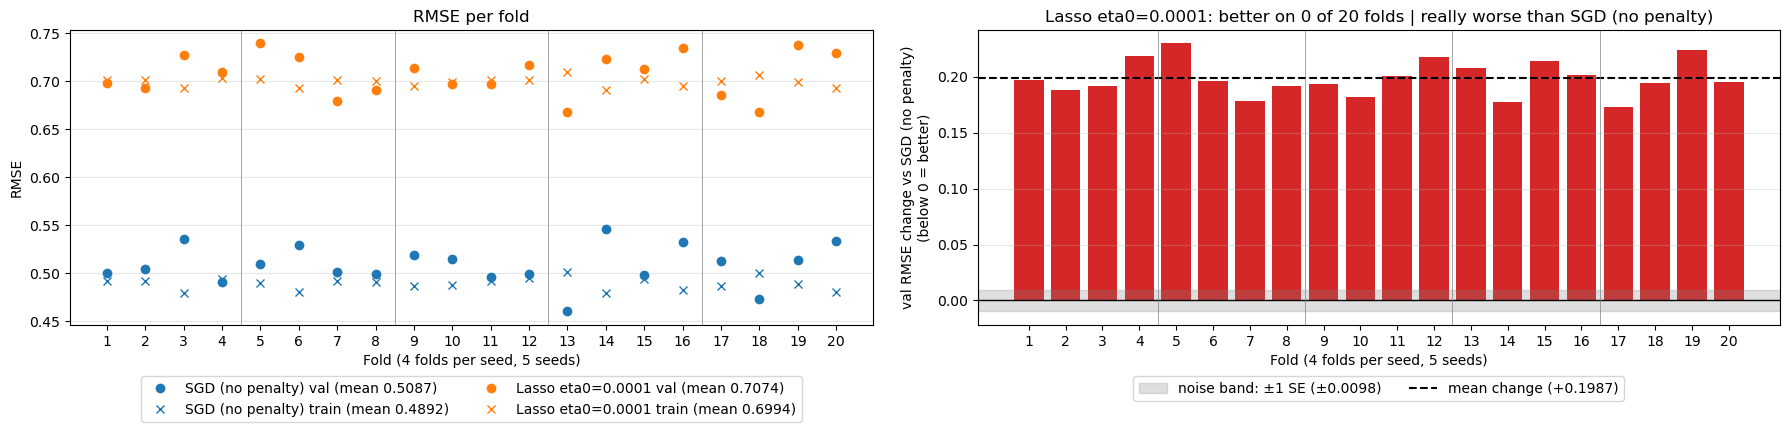

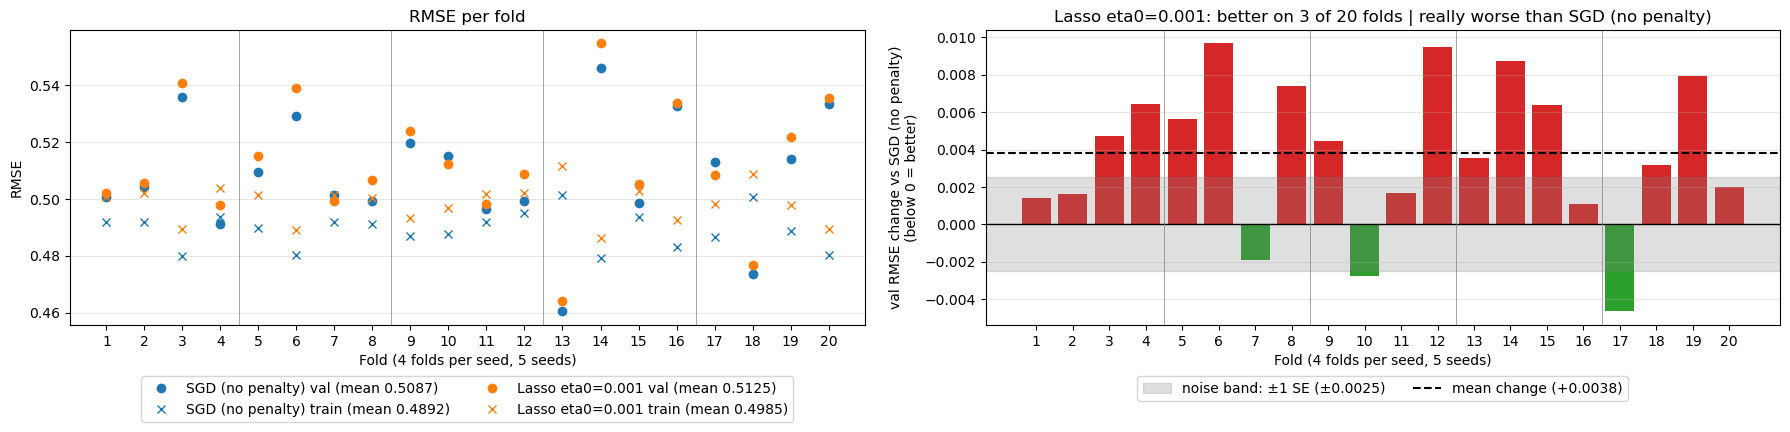

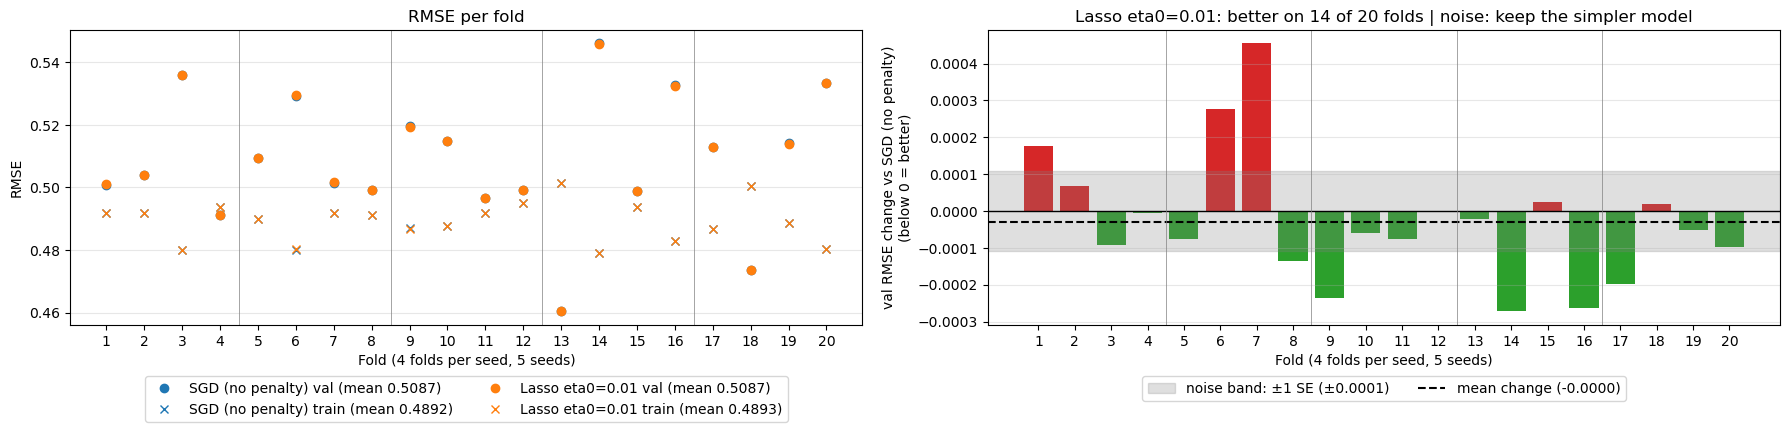

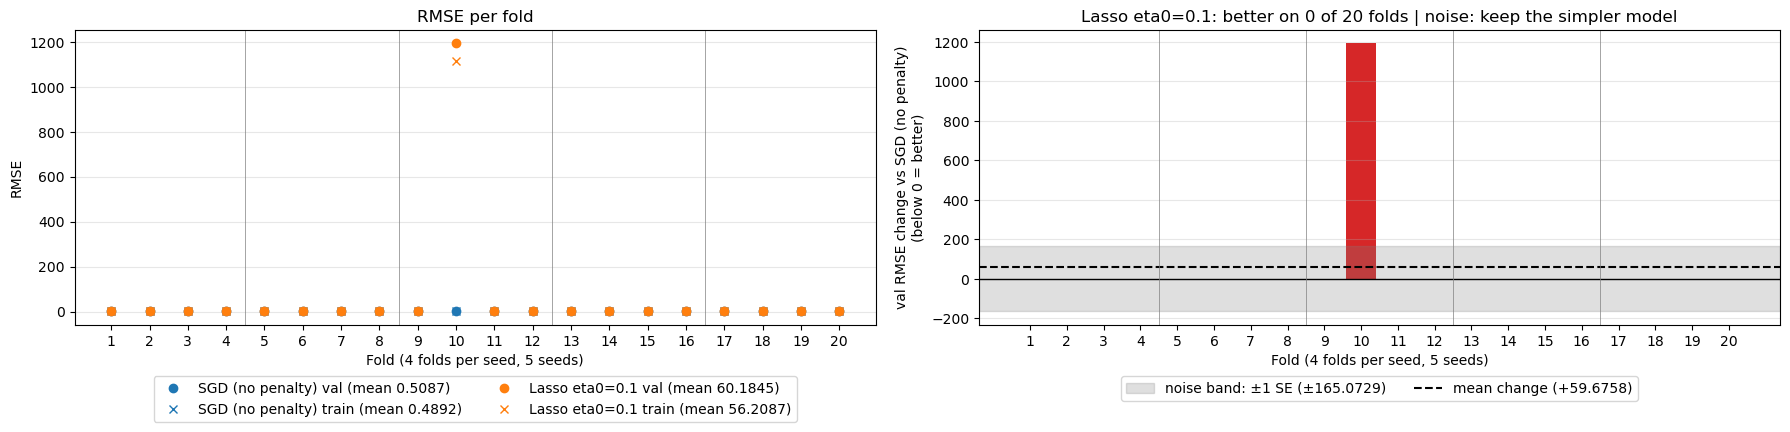

In [17]:
for eta0 in LEARNING_RATES:
	lasso_scores[("eta0", eta0)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty='l1', eta0=eta0, random_state=42),
		),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso eta0={eta0}",
	)

## Ridge

In [18]:
ridge_scores = {}

### Ridge > Penalty

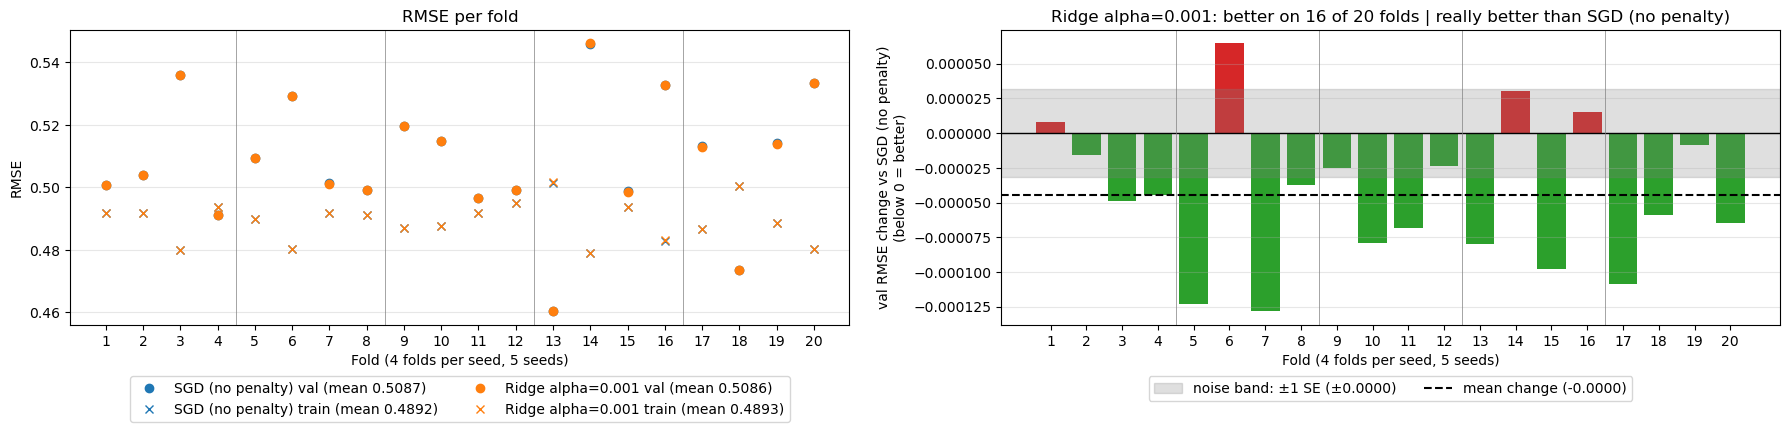

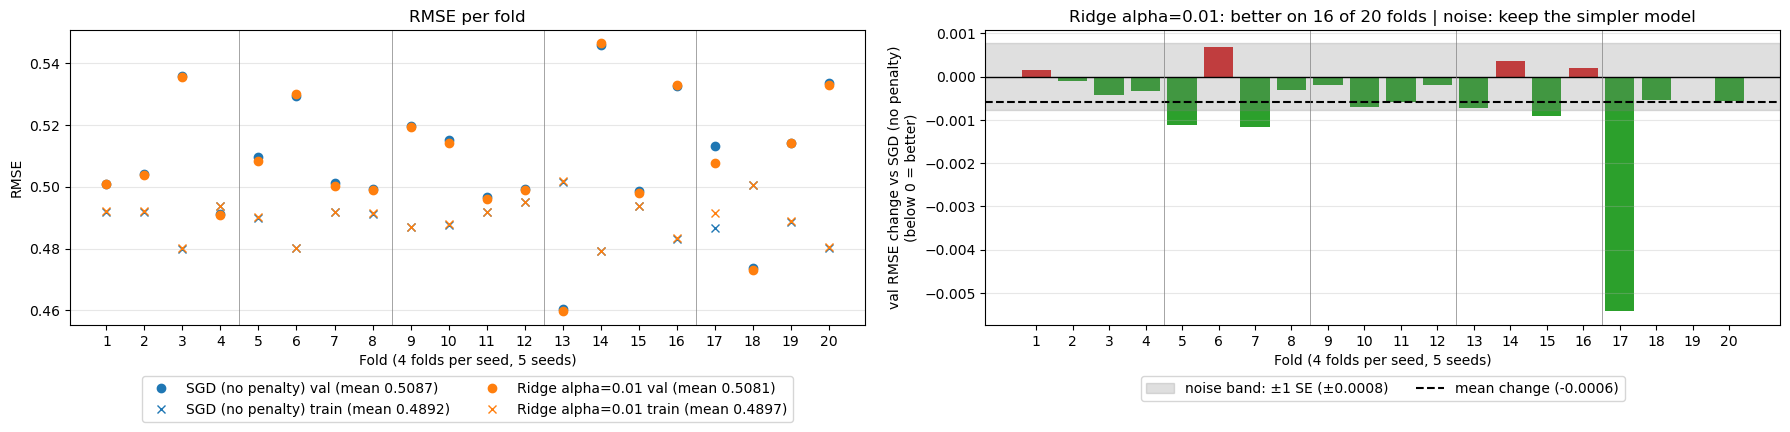

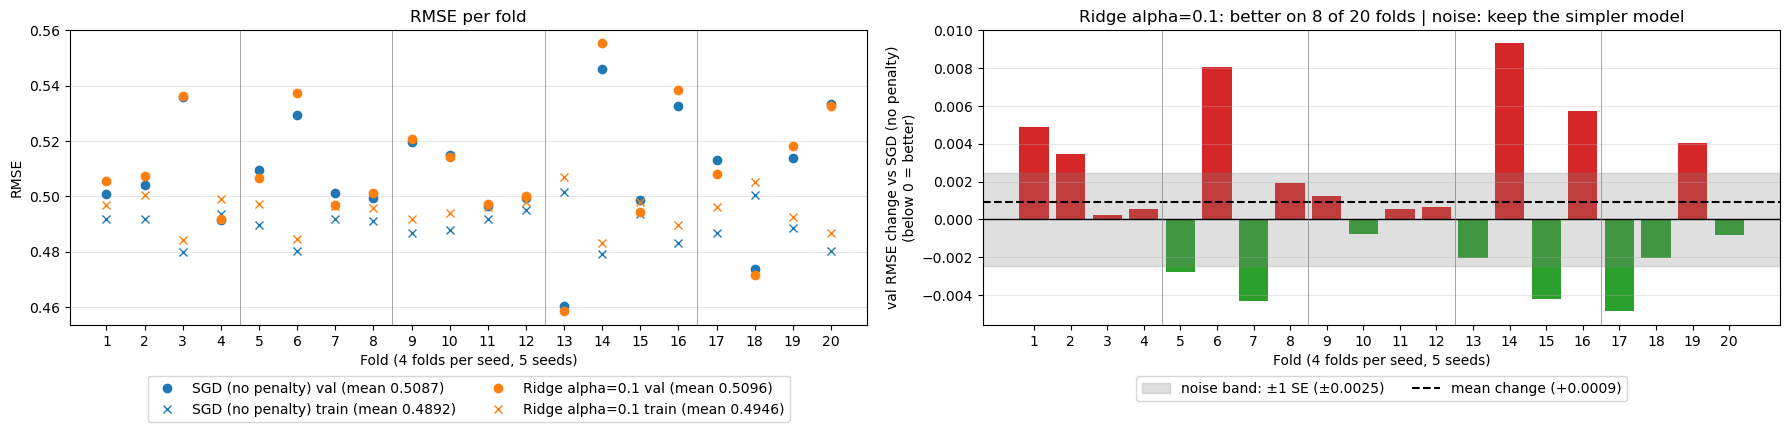

In [19]:
for alpha in ALPHAS:
	ridge_scores[("alpha", alpha)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty='l2', alpha=alpha, random_state=42),
		),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge alpha={alpha}",
	)

### Ridge > Learning Rate

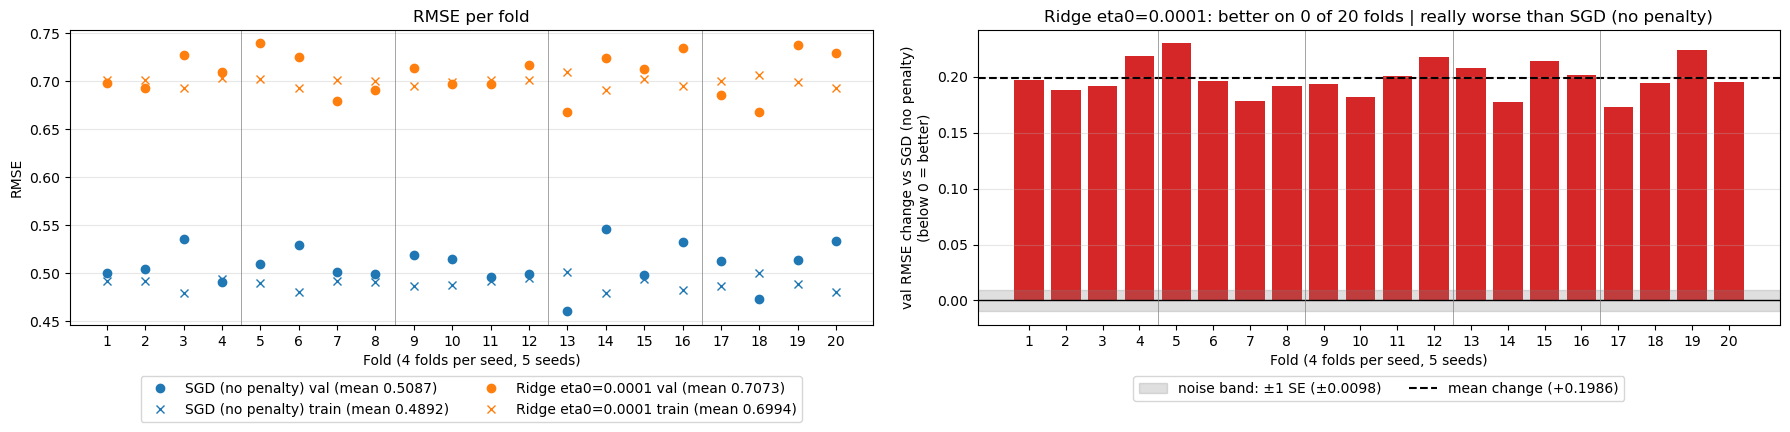

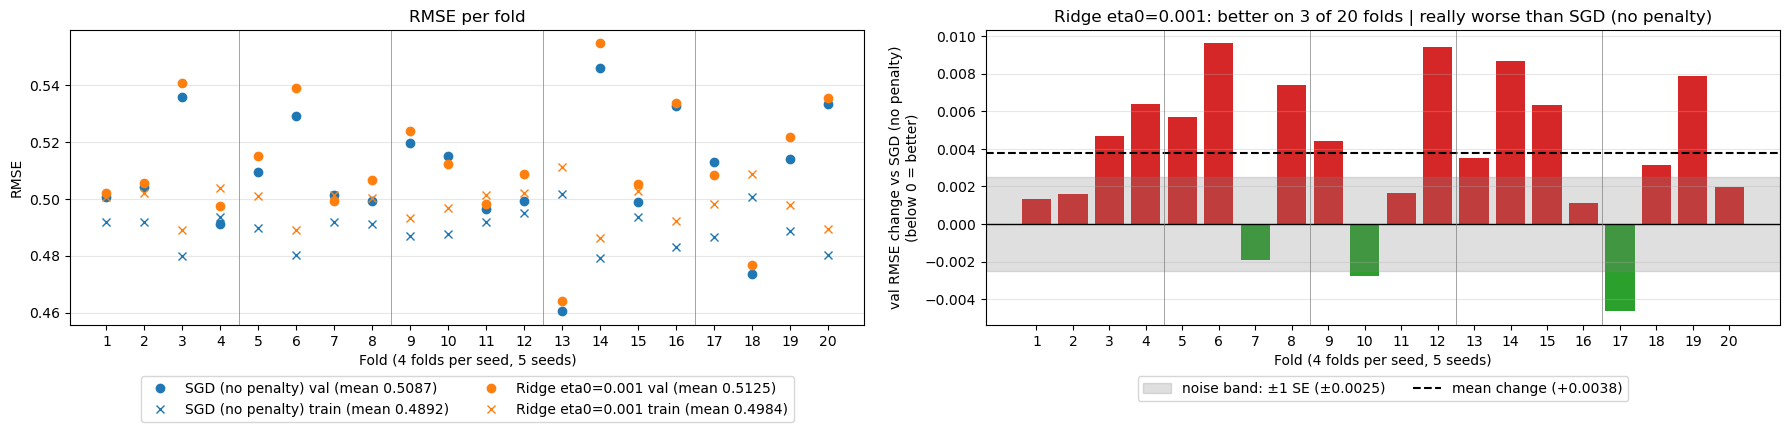

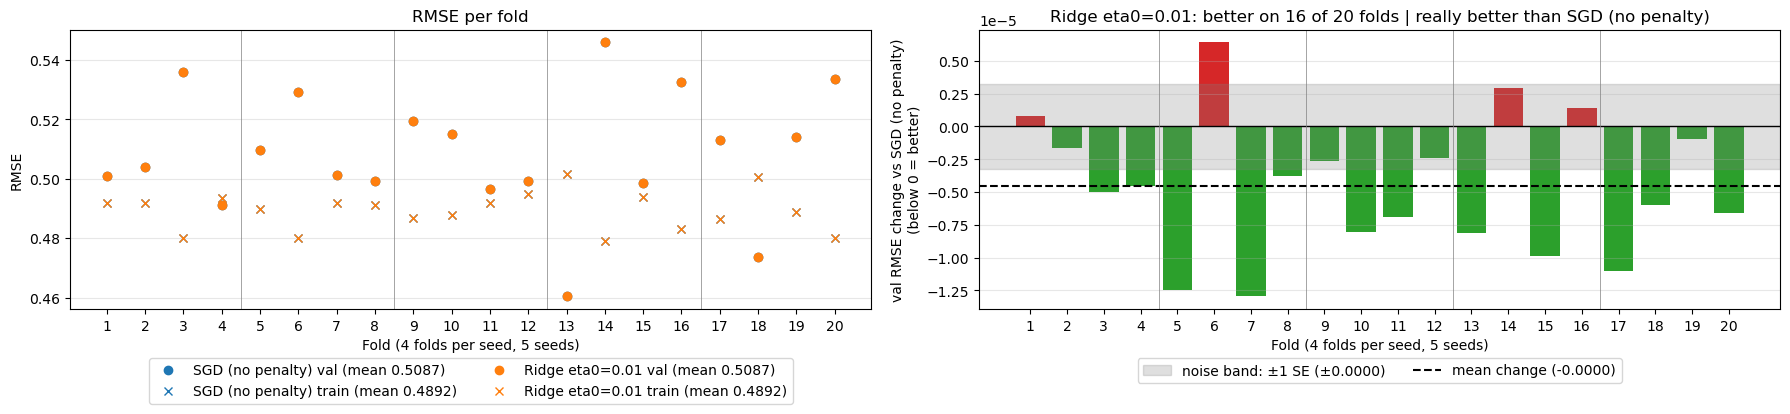

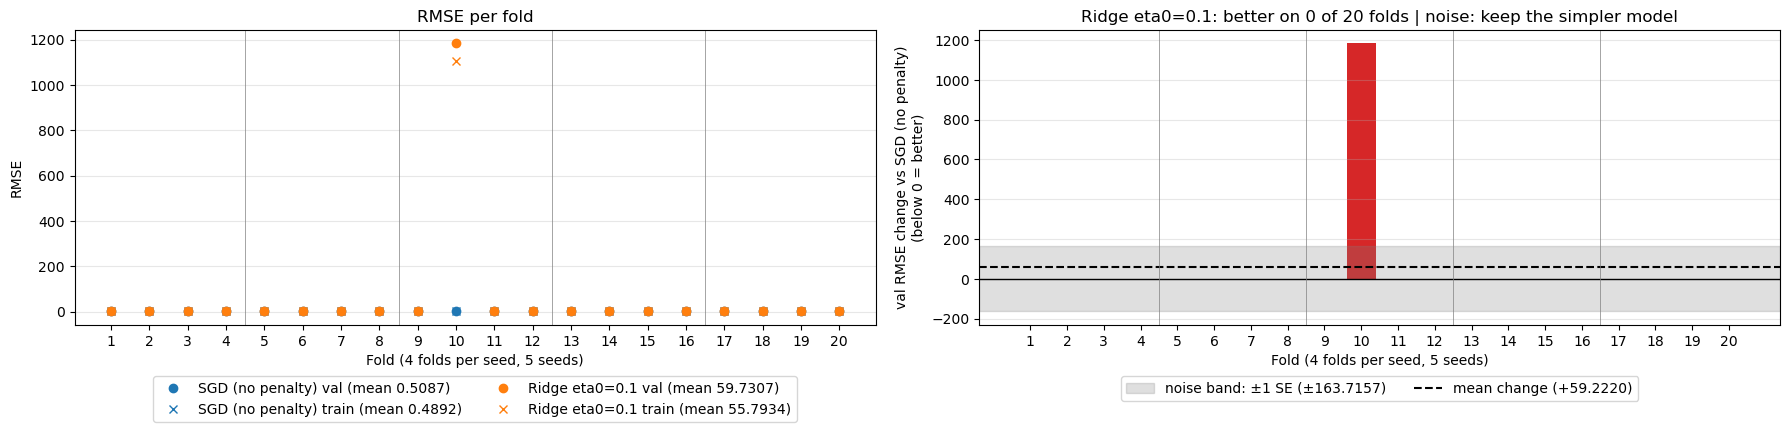

In [20]:
for eta0 in LEARNING_RATES:
	ridge_scores[("eta0", eta0)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty='l2', eta0=eta0, random_state=42),
		),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge eta0={eta0}",
	)

## Elastic Net

In [21]:
elasticnet_scores = {}

### Elastic Net > Penalty

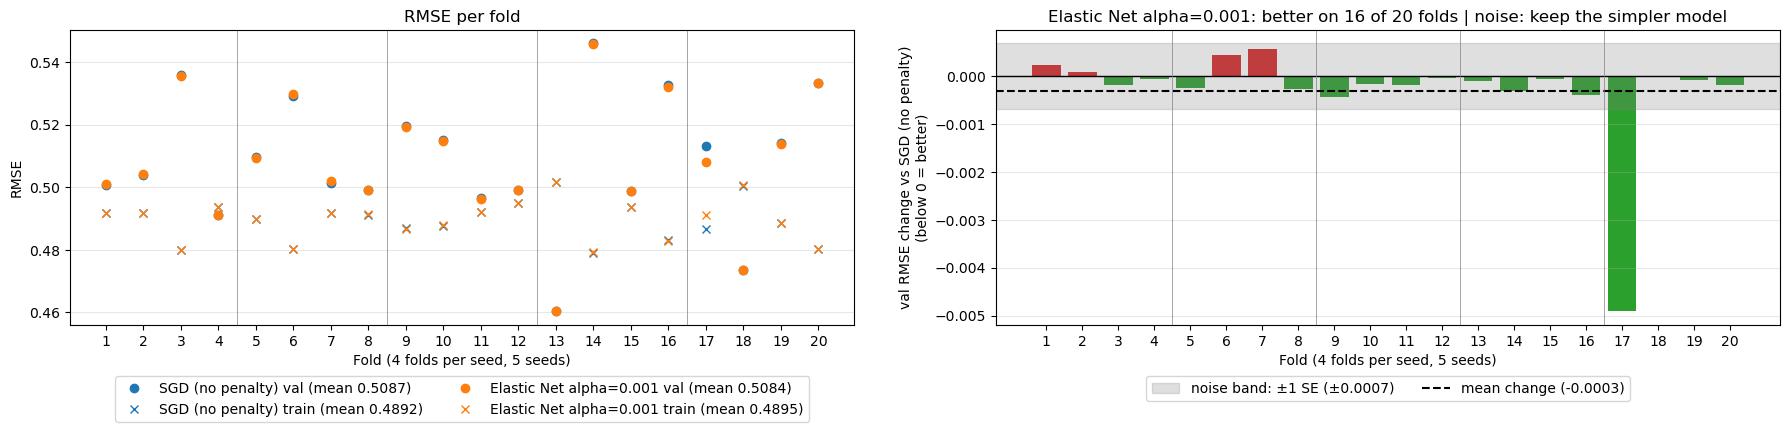

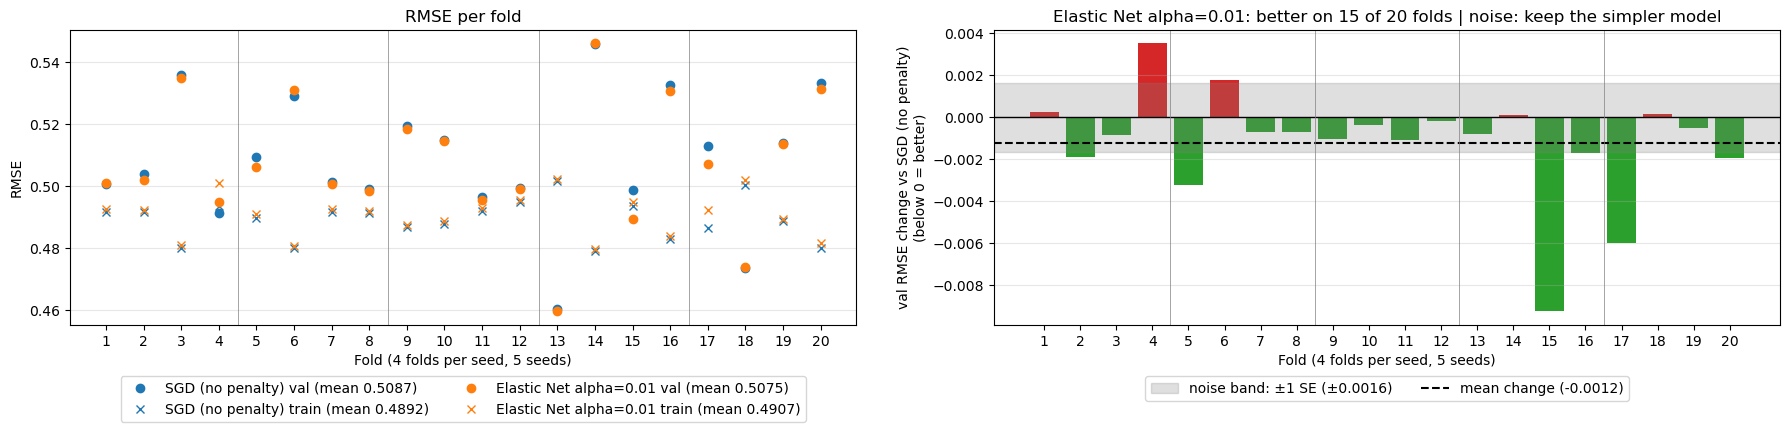

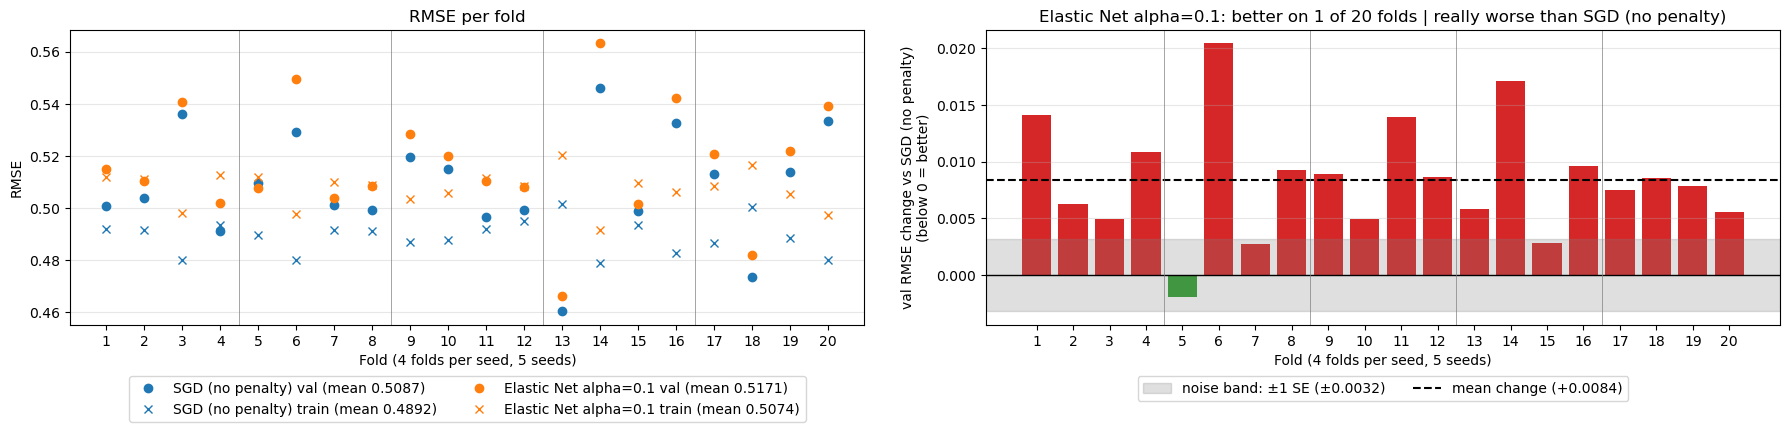

In [22]:
for alpha in ALPHAS:
	elasticnet_scores[("alpha", alpha)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty='elasticnet', alpha=alpha, random_state=42),
		),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net alpha={alpha}",
	)

### Elastic Net > Learning Rate

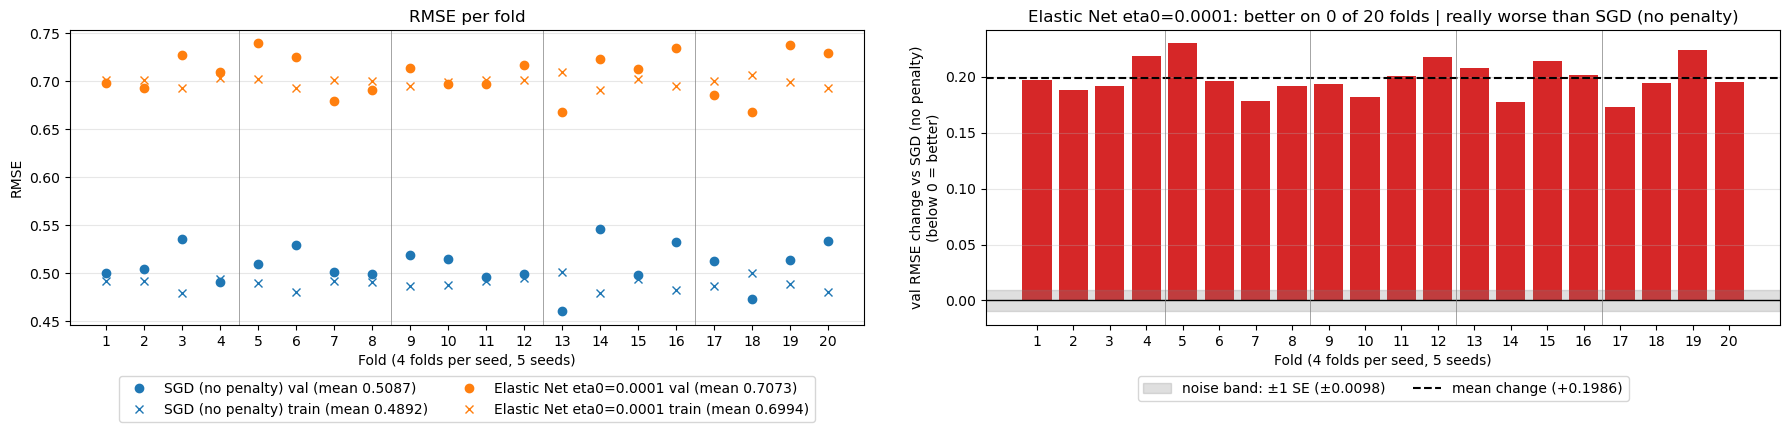

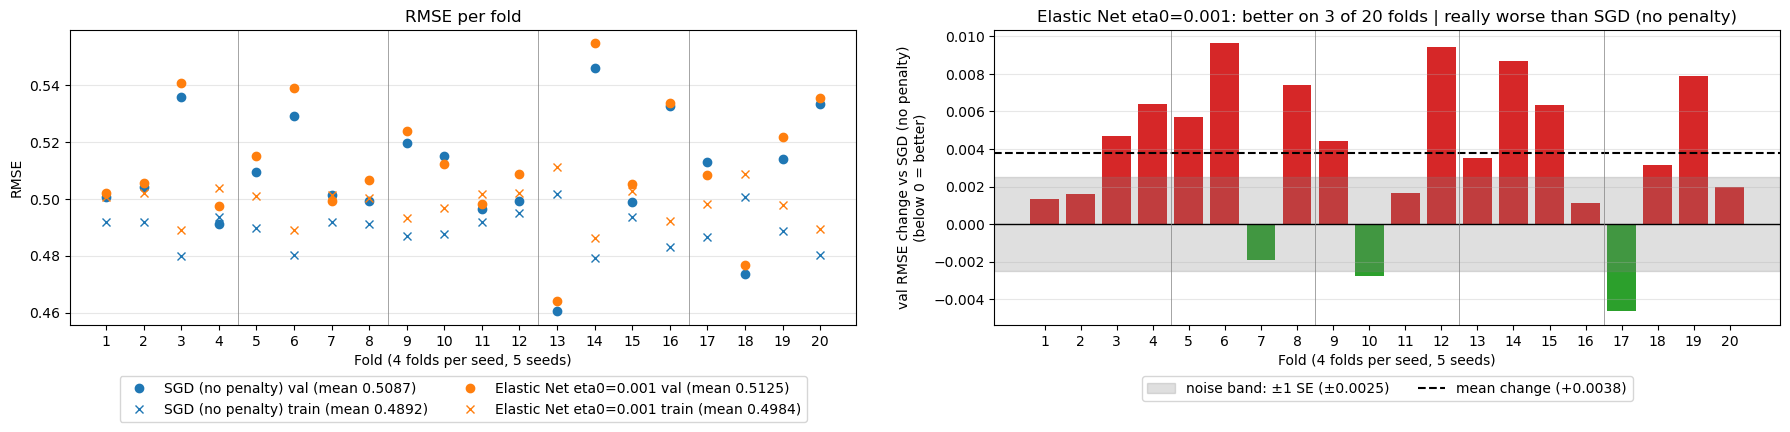

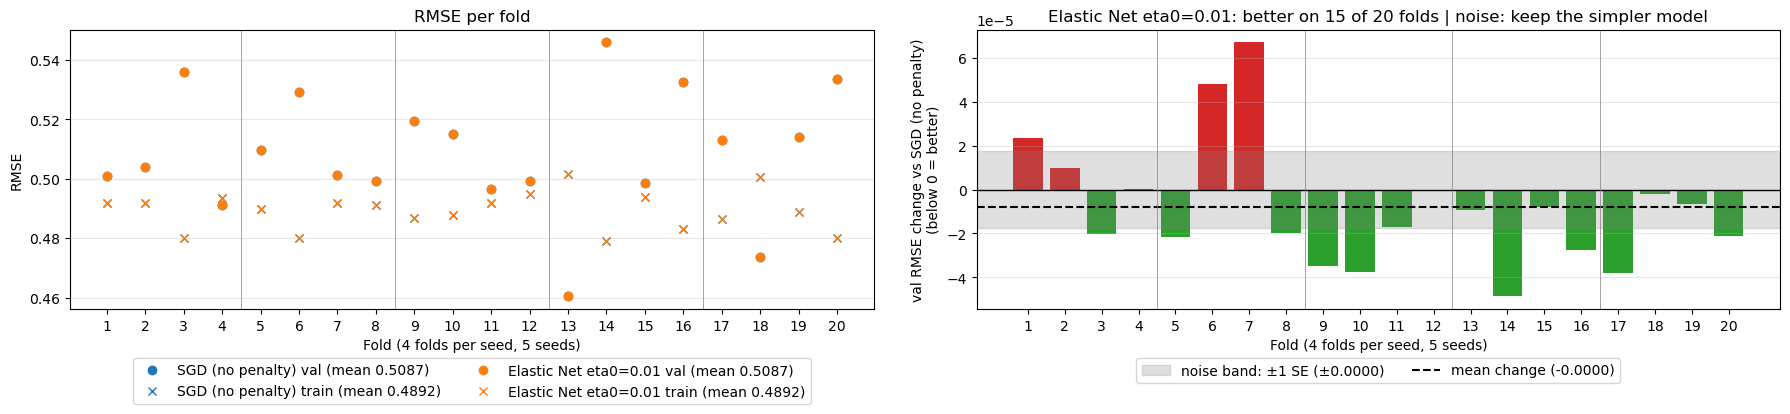

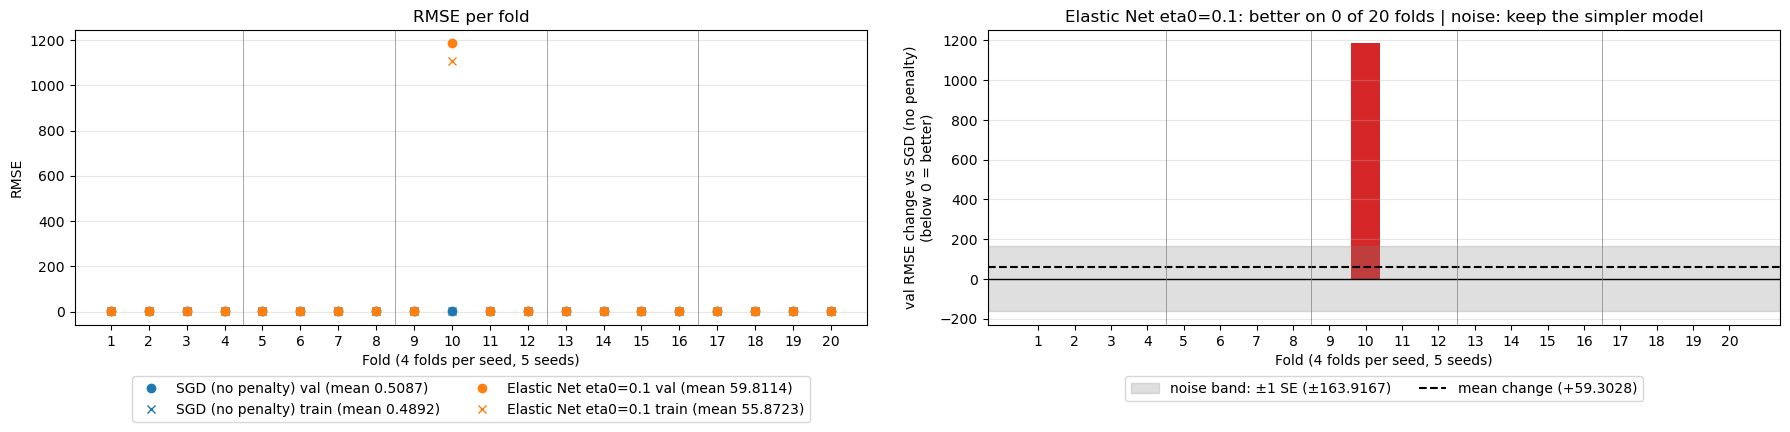

In [23]:
for eta0 in LEARNING_RATES:
	elasticnet_scores[("eta0", eta0)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty='elasticnet', eta0=eta0, random_state=42),
		),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net eta0={eta0}",
	)

## Penalty Summary

In [24]:
runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "alpha":
			runs[f"{name} alpha={value}"] = val_train

summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in runs.items()
}).T.sort_values("change vs SGD")
summary["folds better"] = summary["folds better"].astype(int)
summary["change vs SGD"] = summary["change vs SGD"].map(np.format_float_positional)
summary

,val RMSE,train RMSE,change vs SGD,SE,folds better
Lasso alpha=0.001,0.507425,0.490114,-0.0012608396552267781,0.001690,16
Elastic Net alpha=0.01,0.507460,0.490704,-0.001225398602115163,0.001636,15
Ridge alpha=0.01,0.508090,0.489667,-0.0005957466955400142,0.000763,16
Elastic Net alpha=0.001,0.508375,0.489518,-0.0003107031869530541,0.000689,16
Ridge alpha=0.001,0.508641,0.489253,-0.00004480892381689417,0.000032,16
SGD (no penalty),0.508685,0.489238,0.,0.000000,0
Ridge alpha=0.1,0.509623,0.494595,0.0009378810480147881,0.002472,8
Lasso alpha=0.01,0.511790,0.498610,0.003104394043200248,0.002991,3
Elastic Net alpha=0.1,0.517089,0.507389,0.008403549559203877,0.003202,1
Lasso alpha=0.1,0.553215,0.546948,0.04452968998055458,0.006860,0


**Impact of the penalty.** Each run changes only alpha and leaves eta0 at its default. No penalty gives a gain of any size over plain SGD (0.5087). The lowest scores are Lasso at alpha 0.001 (0.5074, -0.0013, SE 0.0017) and Elastic Net at alpha 0.01 (0.5075, -0.0012, SE 0.0016), both inside the noise. Ridge at alpha 0.01 (0.5081) and Elastic Net at alpha 0.001 (0.5084) are inside the noise too. Ridge at alpha 0.001 is the one chart that reads really better, but only because its change is tiny and consistent: -0.00004 with an SE of 0.00003, which moves the score from 0.5087 to 0.5086.

A stronger penalty makes the model worse, and the three penalties differ in how fast. At alpha 0.1, Ridge is still inside the noise (0.5096, +0.0009, SE 0.0025), Elastic Net is really worse (0.5171, +0.0084, SE 0.0032, better on 1 of 20 folds) and Lasso is really worse by the most (0.5532, +0.0445, SE 0.0069, better on 0 folds). Lasso is already really worse at alpha 0.01 (0.5118, +0.0031, SE 0.0030).

The penalty pushes the model toward underfitting. As alpha grows, training RMSE rises together with validation RMSE: for Lasso, training goes 0.4901, 0.4986, 0.5469 and validation goes 0.5074, 0.5118, 0.5532. At alpha 0.1, Lasso at degree 2 scores worse than closed form at degree 1 (0.5458).

## Learning Rate Summary

In [25]:
learning_rate_runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "eta0":
			learning_rate_runs[f"{name} eta0={value}"] = val_train

learning_rate_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in learning_rate_runs.items()
}).T.sort_values("change vs SGD")
learning_rate_summary["folds better"] = learning_rate_summary["folds better"].astype(int)
learning_rate_summary["change vs SGD"] = learning_rate_summary["change vs SGD"].map(np.format_float_positional)
learning_rate_summary

,val RMSE,train RMSE,change vs SGD,SE,folds better
Lasso eta0=0.01,0.508657,0.489260,-0.000028520928462835716,0.000110,14
Elastic Net eta0=0.01,0.508677,0.489244,-0.00000813118675673241,0.000018,15
Ridge eta0=0.01,0.508681,0.489240,-0.0000045612547587281504,0.000003,16
SGD (no penalty),0.508685,0.489238,0.,0.000000,0
Ridge eta0=0.001,0.512465,0.498402,0.003779713360346865,0.002503,3
Elastic Net eta0=0.001,0.512469,0.498411,0.003783728797069716,0.002504,3
Lasso eta0=0.001,0.512492,0.498462,0.0038061830957645424,0.002509,3
Ridge eta0=0.0001,0.707326,0.699394,0.198640857973554,0.009763,0
Elastic Net eta0=0.0001,0.707331,0.699400,0.19864587720136367,0.009764,0
Lasso eta0=0.0001,0.707360,0.699436,0.1986747229083127,0.009770,0


**Impact of the learning rate.** Each run changes only eta0 and leaves alpha at its default. The three penalties score almost the same at every eta0, so the learning rate is what matters here.

- **eta0 0.01** is the value plain SGD already uses. All three penalties score 0.5087, the same as plain SGD. The Ridge chart reads really better, but its change is in the sixth decimal (-0.000005, SE 0.000003).
- **eta0 0.001** is really worse: 0.5125 (+0.0038, SE 0.0025, better on 3 of 20 folds). Training RMSE is higher too (0.4984 against 0.4892), so the model is less fitted when SGD stops.
- **eta0 0.0001** is really worse by far: 0.7073 (+0.1986, SE 0.0098, better on 0 folds), with training RMSE at 0.6994. The model underfits badly.
- **eta0 0.1** fails. The mean validation RMSE is about 60 (59.73 to 60.18) and it is worse on all 20 folds. The charts show one fold near 1200, where SGD diverges. That one fold pushes the SE to about 164, which is why the three chart titles read noise. The noise rule cannot be trusted for these three runs: they are failures, not ties.

## Hyperparameter Grid
Every combination of penalty, alpha and learning rate (eta0), each compared against plain SGD.

In [26]:
grid_scores = {}
for penalty, alpha, eta0 in product(['l2', 'l1', 'elasticnet'], ALPHAS, LEARNING_RATES):
	grid_scores[(penalty, alpha, eta0)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty=penalty, alpha=alpha, eta0=eta0, random_state=42),
		),
		folds=FOLDS
	)

grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in grid_scores.items()
}).T
grid.index.names = ["penalty", "alpha", "eta0"]
grid["folds better"] = grid["folds better"].astype(int)
grid.sort_values("val RMSE").round(4)

val RMSE  train RMSE  change vs SGD        SE  \
penalty    alpha eta0                                                    
l1         0.001 0.0100    0.5074      0.4901        -0.0013    0.0017   
elasticnet 0.010 0.0100    0.5075      0.4907        -0.0012    0.0016   
l2         0.010 0.0100    0.5081      0.4897        -0.0006    0.0008   
elasticnet 0.001 0.0100    0.5084      0.4895        -0.0003    0.0007   
l2         0.001 0.0100    0.5086      0.4893        -0.0000    0.0000   
           0.100 0.0100    0.5096      0.4946         0.0009    0.0025   
l1         0.010 0.0100    0.5118      0.4986         0.0031    0.0030   
l2         0.001 0.0010    0.5125      0.4984         0.0038    0.0025   
elasticnet 0.001 0.0010    0.5125      0.4985         0.0038    0.0025   
l2         0.010 0.0010    0.5126      0.4987         0.0039    0.0025   
l1         0.001 0.0010    0.5128      0.4991         0.0041    0.0026   
elasticnet 0.010 0.0010    0.5131      0.4997         0.0045    0.0026   
l2         0.100 0.0010    0.5153      0.5028         0.0066    0.0030   
elasticnet 0.100 0.0100    0.5171      0.5074         0.0084    0.0032   
l1         0.010 0.0010    0.5173      0.5066         0.0086    0.0033   
elasticnet 0.100 0.0010    0.5228      0.5146         0.0141    0.0034   
                 0.1000    0.5335      0.5239         0.0248    0.0092   
           0.010 0.1000    0.5512      0.5369         0.0425    0.0158   
l1         0.100 0.0100    0.5532      0.5469         0.0445    0.0069   
                 0.0010    0.5588      0.5539         0.0502    0.0060   
l2         0.010 0.1000    0.5916      0.5825         0.0829    0.0495   
           0.100 0.1000    0.5970      0.5842         0.0883    0.0281   
           0.001 0.0001    0.7073      0.6994         0.1987    0.0098   
elasticnet 0.001 0.0001    0.7074      0.6995         0.1987    0.0098   
l2         0.010 0.0001    0.7075      0.6996         0.1988    0.0098   
l1         0.001 0.0001    0.7077      0.6998         0.1990    0.0098   
elasticnet 0.010 0.0001    0.7081      0.7004         0.1994    0.0100   
l2         0.100 0.0001    0.7100      0.7026         0.2013    0.0100   
l1         0.010 0.0001    0.7110      0.7045         0.2023    0.0103   
elasticnet 0.100 0.0001    0.7148      0.7097         0.2062    0.0104   
l1         0.100 0.0001    0.7391      0.7364         0.2305    0.0136   
                 0.1000   14.9084     14.1150        14.3998   39.6234   
l2         0.001 0.1000   55.1019     51.4704        54.5932  150.8907   
l1         0.010 0.1000   55.1550     51.5267        54.6463  151.2319   
elasticnet 0.001 0.1000   55.7690     52.0860        55.2603  152.7643   
l1         0.001 0.1000   59.7295     55.7840        59.2208  163.8169   

                         folds better  
penalty    alpha eta0                  
l1         0.001 0.0100            16  
elasticnet 0.010 0.0100            15  
l2         0.010 0.0100            16  
elasticnet 0.001 0.0100            16  
l2         0.001 0.0100            16  
           0.100 0.0100             8  
l1         0.010 0.0100             3  
l2         0.001 0.0010             3  
elasticnet 0.001 0.0010             3  
l2         0.010 0.0010             3  
l1         0.001 0.0010             3  
elasticnet 0.010 0.0010             3  
l2         0.100 0.0010             2  
elasticnet 0.100 0.0100             1  
l1         0.010 0.0010             1  
elasticnet 0.100 0.0010             0  
                 0.1000             1  
           0.010 0.1000             0  
l1         0.100 0.0100             0  
                 0.0010             0  
l2         0.010 0.1000             0  
           0.100 0.1000             0  
           0.001 0.0001             0  
elasticnet 0.001 0.0001             0  
l2         0.010 0.0001             0  
l1         0.001 0.0001             0  
elasticnet 0.010 0.0001             0  
l2         0.100 0.0001             0  
l1         0

### Elastic Net l1_ratio
Elastic Net only: l1_ratio sets the mix of the two penalties (0 = all Ridge, 1 = all Lasso). Ridge and Lasso ignore it.

In [27]:
L1_RATIOS = [0.15, 0.5, 0.85]

elasticnet_grid_scores = {}
for alpha, eta0, l1_ratio in product(ALPHAS, LEARNING_RATES, L1_RATIOS):
	elasticnet_grid_scores[(alpha, eta0, l1_ratio)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty='elasticnet', alpha=alpha, eta0=eta0, l1_ratio=l1_ratio, random_state=42),
		),
		folds=FOLDS
	)

elasticnet_grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in elasticnet_grid_scores.items()
}).T
elasticnet_grid.index.names = ["alpha", "eta0", "l1_ratio"]
elasticnet_grid["folds better"] = elasticnet_grid["folds better"].astype(int)
elasticnet_grid.sort_values("val RMSE").round(4)

val RMSE  train RMSE  change vs SGD        SE  \
alpha eta0   l1_ratio                                                  
0.001 0.0100 0.85        0.5074      0.4897        -0.0013    0.0016   
0.010 0.0100 0.15        0.5075      0.4907        -0.0012    0.0016   
0.001 0.0100 0.50        0.5079      0.4896        -0.0008    0.0011   
             0.15        0.5084      0.4895        -0.0003    0.0007   
0.010 0.0100 0.50        0.5088      0.4936         0.0001    0.0019   
             0.85        0.5110      0.4973         0.0023    0.0028   
0.001 0.0010 0.15        0.5125      0.4985         0.0038    0.0025   
             0.50        0.5126      0.4987         0.0039    0.0025   
             0.85        0.5127      0.4990         0.0040    0.0026   
0.010 0.0010 0.15        0.5131      0.4997         0.0045    0.0026   
             0.50        0.5150      0.5025         0.0063    0.0030   
             0.85        0.5166      0.5055         0.0080    0.0032   
0.100 0.0100 0.15        0.5171      0.5074         0.0084    0.0032   
      0.0010 0.15        0.5228      0.5146         0.0141    0.0034   
      0.0100 0.50        0.5303      0.5234         0.0216    0.0048   
      0.1000 0.15        0.5335      0.5239         0.0248    0.0092   
      0.0010 0.50        0.5364      0.5299         0.0277    0.0039   
      0.0100 0.85        0.5461      0.5395         0.0374    0.0063   
      0.1000 0.50        0.5512      0.5454         0.0425    0.0111   
0.010 0.1000 0.15        0.5512      0.5369         0.0425    0.0158   
0.100 0.0010 0.85        0.5518      0.5463         0.0431    0.0056   
      0.1000 0.85        0.5891      0.5820         0.0804    0.0162   
0.001 0.0001 0.15        0.7074      0.6995         0.1987    0.0098   
             0.50        0.7075      0.6996         0.1988    0.0099   
             0.85        0.7076      0.6998         0.1990    0.0098   
0.010 0.0001 0.15        0.7081      0.7004         0.1994    0.0100   
             0.50        0.7095      0.7021         0.2008    0.0101   
             0.85        0.7105      0.7038         0.2018    0.0102   
0.100 0.0001 0.15        0.7148      0.7097         0.2062    0.0104   
             0.50        0.7240      0.7202         0.2153    0.0112   
             0.85        0.7339      0.7309         0.2252    0.0129   
0.010 0.1000 0.50       36.8075     34.3897        36.2988  100.4422   
             0.85       48.8913     45.6765        48.3826  133.8981   
0.001 0.1000 0.15       55.7690     52.0860        55.2603  152.7643   
             0.50       57.3600     53.5729        56.8513  157.2243   
             0.85       59.0138     55.1236        58.5052  161.8098   

                       folds better  
alpha eta0   l1_ratio                
0.001 0.0100 0.85                17  
0.010 0.0100 0.15                15  
0.001 0.0100 0.50                16  
             0.15                16  
0.010 0.0100 0.50                11  
             0.85                 7  
0.001 0.0010 0.15                 3  
             0.50                 3  
             0.85                 3  
0.010 0.0010 0.15                 3  
             0.50                 3  
             0.85                 2  
0.100 0.0100 0.15                 1  
      0.0010 0.15                 0  
      0.0100 0.50                 0  
      0.1000 0.15                 1  
      0.0010 0.50                 0  
      0.0100 0.85                 0  
      0.1000 0.50                 0  
0.010 0.1000 0.15                 0  
0.100 0.0010 0.85                 0  
      0.1000 0.85                 0  
0.001 0.0001 0.15                 0  
             0.50                 0  
             0.85                 0  
0.010 0.0001 0.15                 0  
             0.50                 0  
             0.85                 0  
0.100 0.0001 0.15                 0  
             0.50                 0  
             0.85                 0  
0.010 0.1000 0.50               

**Impact of combining the hyperparameters, and of l1_ratio.** The Hyperparameter Grid sorts mainly by eta0. The 7 best rows all use eta0 0.01 (0.5074 to 0.5118). The best eta0 0.001 row scores 0.5125, and every eta0 0.0001 row scores 0.7073 or worse. eta0 0.1 is the unstable one: its 9 rows run from 0.5335 to 59.73, and 5 of them are above 14. Only the stronger penalties keep it from failing (Elastic Net at alpha 0.1 scores 0.5335), and none of its rows comes close to eta0 0.01.

The best row is Lasso at alpha 0.001 and eta0 0.01 (0.5074, -0.0013, SE 0.0017, better on 16 of 20 folds), the same run as in the Penalty Summary. It is inside the noise, so no combination in the grid is a real improvement over plain SGD.

In the l1_ratio grid at eta0 0.01, the mix matters more as alpha grows, and its direction changes. At alpha 0.001 more Lasso is slightly better (0.5084, 0.5079, 0.5074 for l1_ratio 0.15, 0.5, 0.85), all inside the noise. At alpha 0.01 more Lasso is worse (0.5075, 0.5088, 0.5110), and at alpha 0.1 it is worse by more (0.5171, 0.5303, 0.5461). The best row (alpha 0.001, l1_ratio 0.85: 0.5074, -0.0013, SE 0.0016) is inside the noise.

## Degree Check
The degree was selected with closed form, which has no penalty. This section checks that choice with SGD: the same Hyperparameter Grid one degree higher, compared against plain SGD at degree `BEST_DEGREE`. It shows whether a penalty makes the higher degree worth its extra columns.

In [28]:
CHECK_DEGREE = BEST_DEGREE + 1

degree_check_scores = {}
for penalty, alpha, eta0 in product(['l2', 'l1', 'elasticnet'], ALPHAS, LEARNING_RATES):
	degree_check_scores[(penalty, alpha, eta0)] = cross_validation.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=make_pipeline(
			StandardScaler(),
			PolynomialFeatures(degree=CHECK_DEGREE, include_bias=False),
			StandardScaler(),
			SGDRegressor(penalty=penalty, alpha=alpha, eta0=eta0, random_state=42),
		),
		folds=FOLDS
	)

degree_check = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in degree_check_scores.items()
}).T
degree_check.index.names = ["penalty", "alpha", "eta0"]
degree_check["folds better"] = degree_check["folds better"].astype(int)

# a run that diverged has a val RMSE in the hundreds or more. Those rows are counted here and left out of
# the table, because numbers that large would force the whole table into scientific notation.
diverged = degree_check["val RMSE"] > 10
print(f"diverged (val RMSE above 10): {diverged.sum()} of {len(degree_check)} runs, at eta0 values {sorted(set(degree_check[diverged].index.get_level_values('eta0')))}")
degree_check[~diverged].sort_values("val RMSE").round(4)

diverged (val RMSE above 10): 18 of 36 runs, at eta0 values [0.01, 0.1]


val RMSE  train RMSE  change vs SGD      SE  \
penalty    alpha eta0                                                  
elasticnet 0.010 0.0010    0.5007      0.4674        -0.0079  0.0066   
l1         0.001 0.0010    0.5008      0.4657        -0.0079  0.0070   
elasticnet 0.001 0.0010    0.5011      0.4637        -0.0076  0.0080   
l2         0.001 0.0010    0.5012      0.4634        -0.0075  0.0082   
           0.010 0.0010    0.5014      0.4641        -0.0072  0.0081   
           0.100 0.0010    0.5055      0.4714        -0.0032  0.0078   
l1         0.010 0.0010    0.5075      0.4851        -0.0011  0.0037   
elasticnet 0.100 0.0010    0.5158      0.4981         0.0071  0.0038   
l1         0.100 0.0010    0.5544      0.5463         0.0458  0.0053   
           0.001 0.0001    0.7035      0.6812         0.1948  0.0115   
elasticnet 0.001 0.0001    0.7037      0.6802         0.1950  0.0117   
l2         0.001 0.0001    0.7037      0.6800         0.1951  0.0118   
elasticnet 0.010 0.0001    0.7038      0.6821         0.1951  0.0114   
l2         0.010 0.0001    0.7040      0.6804         0.1954  0.0118   
l1         0.010 0.0001    0.7064      0.6917         0.1977  0.0113   
l2         0.100 0.0001    0.7071      0.6844         0.1984  0.0123   
elasticnet 0.100 0.0001    0.7109      0.6986         0.2022  0.0119   
l1         0.100 0.0001    0.7369      0.7313         0.2282  0.0142   

                         folds better  
penalty    alpha eta0                  
elasticnet 0.010 0.0010            15  
l1         0.001 0.0010            15  
elasticnet 0.001 0.0010            15  
l2         0.001 0.0010            15  
           0.010 0.0010            15  
           0.100 0.0010            15  
l1         0.010 0.0010            12  
elasticnet 0.100 0.0010             2  
l1         0.100 0.0010             0  
           0.001 0.0001             0  
elasticnet 0.001 0.0001             0  
l2         0.001 0.0001             0  
elasticnet 0.010 0.0001             0  
l2         0.010 0.0001             0  
l1         0.010 0.0001             0  
l2         0.100 0.0001             0  
elasticnet 0.100 0.0001             0  
l1         0.100 0.0001             0

**Does a penalty make the higher degree worth it?** Degree 3 cannot use the learning rate that works at degree 2. All 18 runs at eta0 0.01 and 0.1 diverge, and at eta0 0.0001 every run underfits (0.7035 or worse). Only eta0 0.001 works.

At eta0 0.001, degree 3 scores lower than anything at degree 2. The two best rows are Elastic Net at alpha 0.01 (0.5007, -0.0079, SE 0.0066) and Lasso at alpha 0.001 (0.5008, -0.0079, SE 0.0070), each better on 15 of 20 folds. Both clear the 1 SE rule against plain SGD at degree 2 (0.5087), but narrowly. The next three rows (0.5011 to 0.5014) do not: each change is smaller than its SE.

The penalty is not what makes degree 3 work. The weakest penalty in the grid (Ridge at alpha 0.001) already scores 0.5012, within 0.0005 of the best row, and a strong penalty makes degree 3 worse just as it does at degree 2 (Lasso at alpha 0.1: 0.5544).

Two cautions. First, degree 3 fits the training rows much more closely than it predicts the validation rows (0.4674 and 0.5007 for the best row, against 0.4892 and 0.5087 for plain SGD at degree 2), which is the direction of overfitting. Second, this table compares with plain SGD at degree 2, not with the best degree 2 row (0.5074), and its best row is the best of 36. The Selected Model section compares the two candidates directly, fold by fold.

# Selected Model
The best-performing row of the Hyperparameter Grid at degree `BEST_DEGREE`, typed in by hand.

In [29]:
BEST_PENALTY = 'l1'
BEST_ALPHA = 0.001
BEST_ETA0 = 0.01

best_val_scores, best_train_scores = grid_scores[(BEST_PENALTY, BEST_ALPHA, BEST_ETA0)]
print(f"val RMSE {best_val_scores.mean():.4f} | train RMSE {best_train_scores.mean():.4f}")

val RMSE 0.5074 | train RMSE 0.4901


## Selected Model Against the Best Degree 3 Row
The Degree Check left one question open: is the best degree 3 row really better than the best degree 2 row? The two are compared here on the same 20 folds. The degree 3 row is typed in by hand from the Degree Check table.

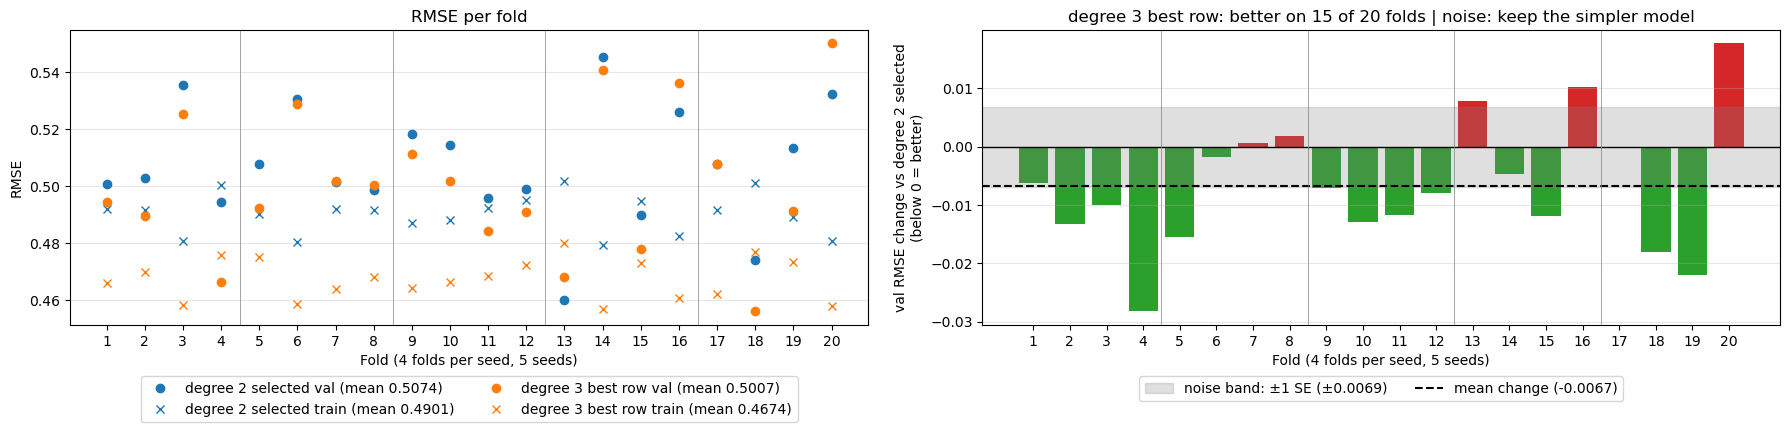

In [30]:
CHECK_PENALTY = 'elasticnet'
CHECK_ALPHA = 0.01
CHECK_ETA0 = 0.001

check_val_scores, check_train_scores = degree_check_scores[(CHECK_PENALTY, CHECK_ALPHA, CHECK_ETA0)]

cv_fold_scores(
	baseline=(best_val_scores, best_train_scores),
	compare=(check_val_scores, check_train_scores),
	baseline_name=f"degree {BEST_DEGREE} selected",
	compare_name=f"degree {CHECK_DEGREE} best row",
)

**Degree 2 or degree 3.** The selected degree 2 row (Lasso, alpha 0.001, eta0 0.01) scores a validation RMSE of 0.5074. It is the best-performing row of the grid, although it is inside the noise of plain SGD (0.5087). The best degree 3 row (Elastic Net, alpha 0.01, eta0 0.001) scores 0.5007 and is better on 15 of 20 folds. The mean change of -0.0067 sits just inside the edge of the ±0.0069 noise band, so the verdict is noise and the simpler model is kept.

This is a close call, and three things support staying at degree 2. It has 44 columns where degree 3 has 164. Its training and validation RMSE are closer together (0.4901 and 0.5074, against 0.4674 and 0.5007 at degree 3). And it runs at eta0 0.01, where every degree 3 run diverged. The selected model is degree 2 with Lasso at alpha 0.001 and eta0 0.01.

## Train on the Entire Training Set
The selected model is fit once on every complete training row, with SGD's default stopping rule.

In [31]:
final_train_df = train_df.dropna()
print(f"rows: {len(final_train_df)}")

final_model = make_pipeline(
	StandardScaler(),
	PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
	StandardScaler(),
	SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, random_state=42),
)
final_model.fit(final_train_df[FEATURES], final_train_df[TARGET])

final_train_rmse = cross_validation.rmse_of(final_train_df[TARGET], final_model.predict(final_train_df[FEATURES]))
print(f"train RMSE {final_train_rmse:.4f} | epochs run {final_model[-1].n_iter_}")

rows: 1374
train RMSE 0.4952 | epochs run 12


**Final model.** The selected model (degree 2, Lasso, alpha 0.001, eta0 0.01) is trained on the 1374 complete training rows. The 185 incomplete rows are left out, because the Missing Rows section found no gain from imputing them. SGD stops after 12 epochs with a training RMSE of 0.4952, in line with the cross-validated training RMSE of 0.4901. This model has no validation score of its own, because every complete row is used for training. The cross-validated 0.5074 is the estimate of its error on new rows.

## Save the Model
The fitted pipeline is saved to `Q1/MODELS`, so Part F can load it and predict on the test data.

In [32]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / 'polynomial_regression.joblib'
joblib.dump(final_model, model_path)
print(f"saved: {model_path.name}")

saved: polynomial_regression.joblib


## Training and Validation Loss by Epoch
A validation loss needs rows the model has not trained on, so this curve uses the first fold: the model trains on that fold's training rows and is scored on its validation rows after every epoch. Each `fit` call runs exactly one epoch (`max_iter=1`) and continues from the previous call (`warm_start=True`).

In [33]:
EPOCHS = 30

train_index, val_index = FOLDS[0]
epoch_train_df = train_df.loc[train_index].dropna()
epoch_val_df = train_df.loc[val_index]
print(f"train rows: {len(epoch_train_df)} | validation rows: {len(epoch_val_df)}")

epoch_model = make_pipeline(
	StandardScaler(),
	PolynomialFeatures(degree=BEST_DEGREE, include_bias=False),
	StandardScaler(),
	SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, max_iter=1, tol=None, warm_start=True, random_state=42),
)

epoch_train_rmse, epoch_val_rmse = [], []
for epoch in range(EPOCHS):
	# one more epoch, continuing from the coefficients of the previous call
	epoch_model.fit(epoch_train_df[FEATURES], epoch_train_df[TARGET])
	epoch_train_rmse.append(
		cross_validation.rmse_of(epoch_train_df[TARGET], epoch_model.predict(epoch_train_df[FEATURES])))
	epoch_val_rmse.append(cross_validation.rmse_of(epoch_val_df[TARGET], epoch_model.predict(epoch_val_df[FEATURES])))

epoch_scores = pd.DataFrame(
	{"train RMSE": epoch_train_rmse, "val RMSE": epoch_val_rmse},
	index=pd.RangeIndex(1, EPOCHS + 1, name="epoch"),
)
epoch_scores.loc[[1, 2, 3, 4, 5, 10, 15, 20, 30]].round(4)

train rows: 1030 | validation rows: 344


,train RMSE,val RMSE
epoch,,
1,0.7115,0.7185
2,0.5110,0.5074
3,0.5032,0.5025
4,0.5008,0.5034
5,0.4995,0.5039
10,0.4972,0.5052
15,0.4966,0.5054
20,0.4964,0.5054
30,0.4964,0.5055


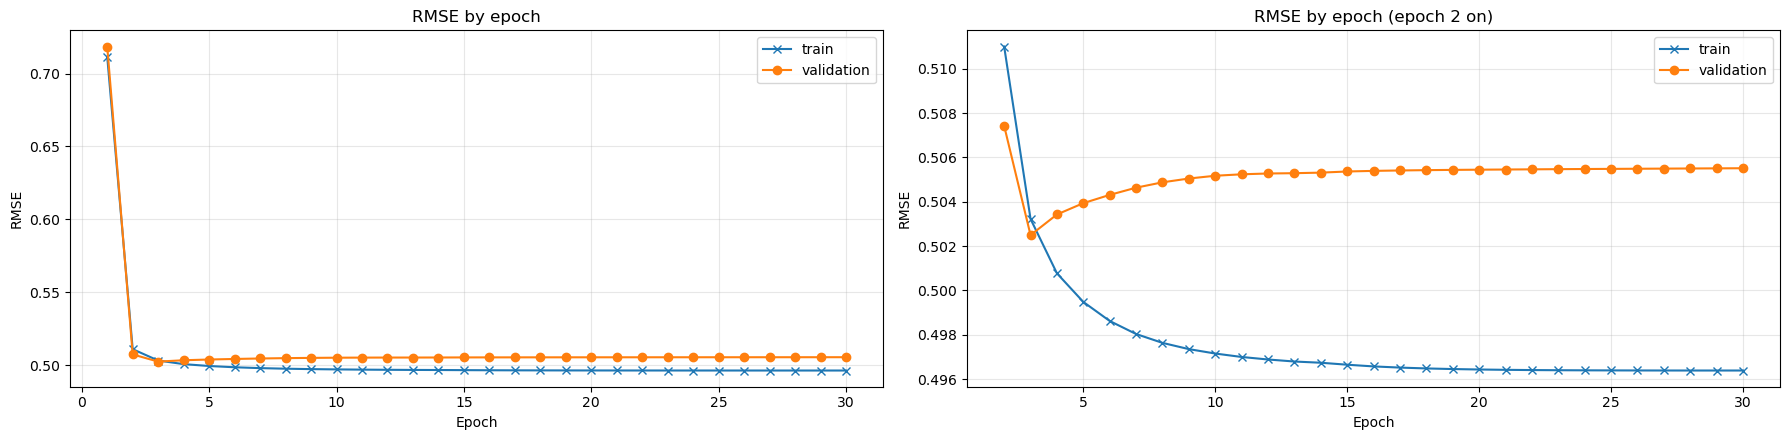

In [34]:
fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(18, 4.5))

# left: every epoch. right: from epoch 2 on, where the two lines can be told apart
for ax, scores, title in [
	(ax_all, epoch_scores, "RMSE by epoch"),
	(ax_zoom, epoch_scores.loc[2:], "RMSE by epoch (epoch 2 on)"),
]:
	ax.plot(scores.index, scores["train RMSE"], "x-", color="C0", label="train")
	ax.plot(scores.index, scores["val RMSE"], "o-", color="C1", label="validation")
	ax.set_xlabel("Epoch")
	ax.set_ylabel("RMSE")
	ax.set_title(title)
	ax.grid(alpha=0.3)
	ax.legend()

plt.tight_layout()
plt.show()

**Training and validation loss by epoch.** The curve uses the first fold: 1030 training rows and 344 validation rows. Most of the learning happens in the first two epochs. Training RMSE falls from 0.7115 to 0.5110 and validation RMSE from 0.7185 to 0.5074.

Validation RMSE is lowest at epoch 3 (0.5025). After that the two lines separate. Training RMSE keeps falling slowly (0.5032 at epoch 3, 0.4972 at epoch 10, 0.4964 at epoch 30), while validation RMSE drifts up (0.5034 at epoch 4, 0.5052 at epoch 10, 0.5055 at epoch 30). Training still improving while validation gets worse is overfitting, but here it is mild: validation ends 0.0030 above its lowest point, and both lines are flat from about epoch 15 (0.4966 and 0.5054 at epoch 15, 0.4964 and 0.5055 at epoch 30). Training longer neither helps nor hurts. The final model above stopped after 12 epochs, in the flat part of this curve.

# Overfitting and Underfitting
The assignment asks whether the model overfits or underfits, judged by validation loss. Two views are already above: by degree (Degree Summary) and by penalty strength (Penalty Summary). This section adds the third view, by epoch, for degrees 1, 2 and 3.

## Loss by Epoch for Degrees 1, 2 and 3
Plain SGD (no penalty) on the first fold, the same rows as the curve above. The degree is the only thing that changes. All three degrees use eta0 0.001, the only learning rate in the grid at which degree 3 does not diverge. That learning rate is slow, so the curves run for 1000 epochs.

In [35]:
CURVE_EPOCHS = 1000
CURVE_ETA0 = 0.001

curve_scores = {}
for degree in [1, 2, 3]:
	curve_model = make_pipeline(
		StandardScaler(),
		PolynomialFeatures(degree=degree, include_bias=False),
		StandardScaler(),
		SGDRegressor(penalty=None, eta0=CURVE_ETA0, max_iter=1, tol=None, warm_start=True, random_state=42),
	)

	curve_train_rmse, curve_val_rmse = [], []
	for epoch in range(CURVE_EPOCHS):
		# one more epoch, continuing from the coefficients of the previous call
		curve_model.fit(epoch_train_df[FEATURES], epoch_train_df[TARGET])
		curve_train_rmse.append(
			cross_validation.rmse_of(epoch_train_df[TARGET], curve_model.predict(epoch_train_df[FEATURES])))
		curve_val_rmse.append(cross_validation.rmse_of(epoch_val_df[TARGET], curve_model.predict(epoch_val_df[FEATURES])))

	curve_scores[f"degree {degree}"] = pd.DataFrame(
		{"train RMSE": curve_train_rmse, "val RMSE": curve_val_rmse},
		index=pd.RangeIndex(1, CURVE_EPOCHS + 1, name="epoch"),
	)
	print(f"degree {degree}: lowest val RMSE {min(curve_val_rmse):.4f} at epoch {curve_scores[f'degree {degree}']['val RMSE'].idxmin()}")

pd.concat(curve_scores, axis=1).loc[[1, 10, 20, 30, 50, 100, 200, 400, 600, 800, 1000]].round(4)

degree 1: lowest val RMSE 0.5531 at epoch 21
degree 2: lowest val RMSE 0.4942 at epoch 27
degree 3: lowest val RMSE 0.4840 at epoch 67


degree 1            degree 2            degree 3         
      train RMSE val RMSE train RMSE val RMSE train RMSE val RMSE
epoch                                                            
1         4.3319   4.3318     4.3259   4.3200     4.3293   4.3556
10        0.7304   0.7204     0.7028   0.6977     0.6871   0.7198
20        0.5421   0.5533     0.4981   0.4964     0.4621   0.4962
30        0.5392   0.5541     0.4926   0.4943     0.4500   0.4874
50        0.5385   0.5548     0.4901   0.4956     0.4407   0.4844
100       0.5382   0.5549     0.4888   0.4973     0.4315   0.4846
200       0.5382   0.5549     0.4886   0.4979     0.4248   0.4879
400       0.5382   0.5549     0.4886   0.4981     0.4200   0.4953
600       0.5382   0.5549     0.4886   0.4982     0.4180   0.5017
800       0.5382   0.5549     0.4886   0.4982     0.4169   0.5067
1000      0.5382   0.5549     0.4886   0.4982     0.4162   0.5107

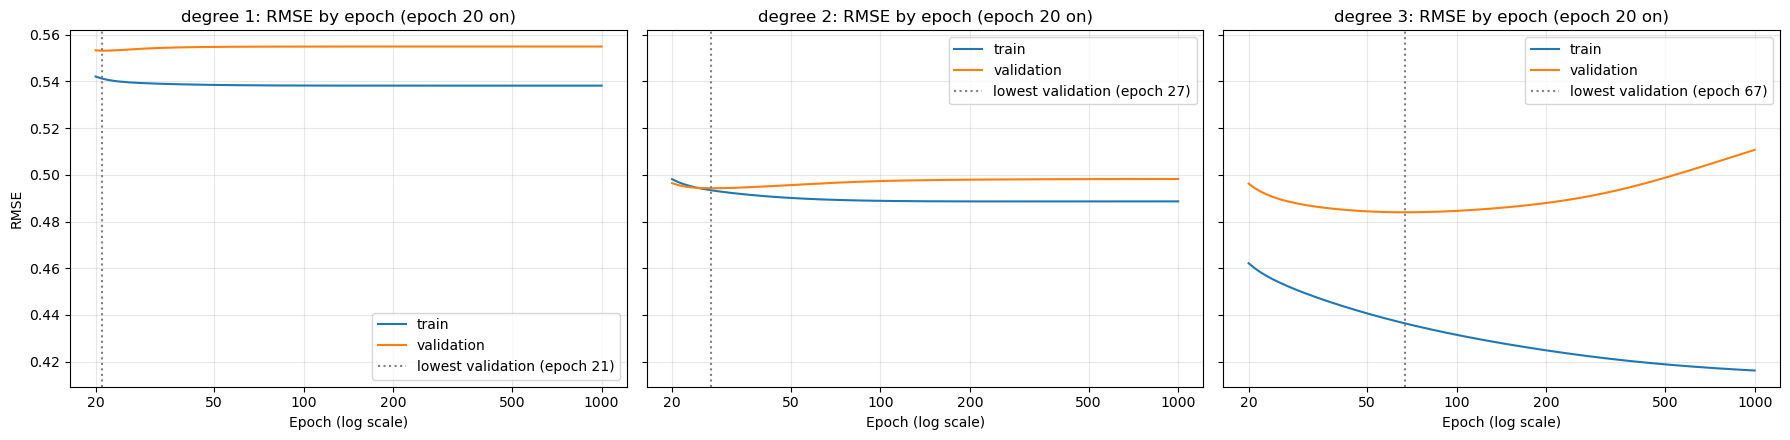

In [36]:
CURVE_FIRST_EPOCH = 20

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

# the first epochs are left out: RMSE starts above 4 and would flatten everything after it.
# the x axis is a log scale, so the early epochs and the long tail can both be read
for ax, (name, scores) in zip(axes, curve_scores.items()):
	best_epoch = scores["val RMSE"].idxmin()
	scores = scores.loc[CURVE_FIRST_EPOCH:]
	ax.plot(scores.index, scores["train RMSE"], color="C0", label="train")
	ax.plot(scores.index, scores["val RMSE"], color="C1", label="validation")
	ax.axvline(best_epoch, color="gray", linestyle=":", label=f"lowest validation (epoch {best_epoch})")
	ax.set_xscale("log")
	ax.set_xticks([20, 50, 100, 200, 500, 1000])
	ax.set_xticklabels([20, 50, 100, 200, 500, 1000])
	ax.minorticks_off()
	ax.set_xlabel("Epoch (log scale)")
	ax.set_title(f"{name}: RMSE by epoch (epoch {CURVE_FIRST_EPOCH} on)")
	ax.grid(alpha=0.3)
	ax.legend()
axes[0].set_ylabel("RMSE")

plt.tight_layout()
plt.show()

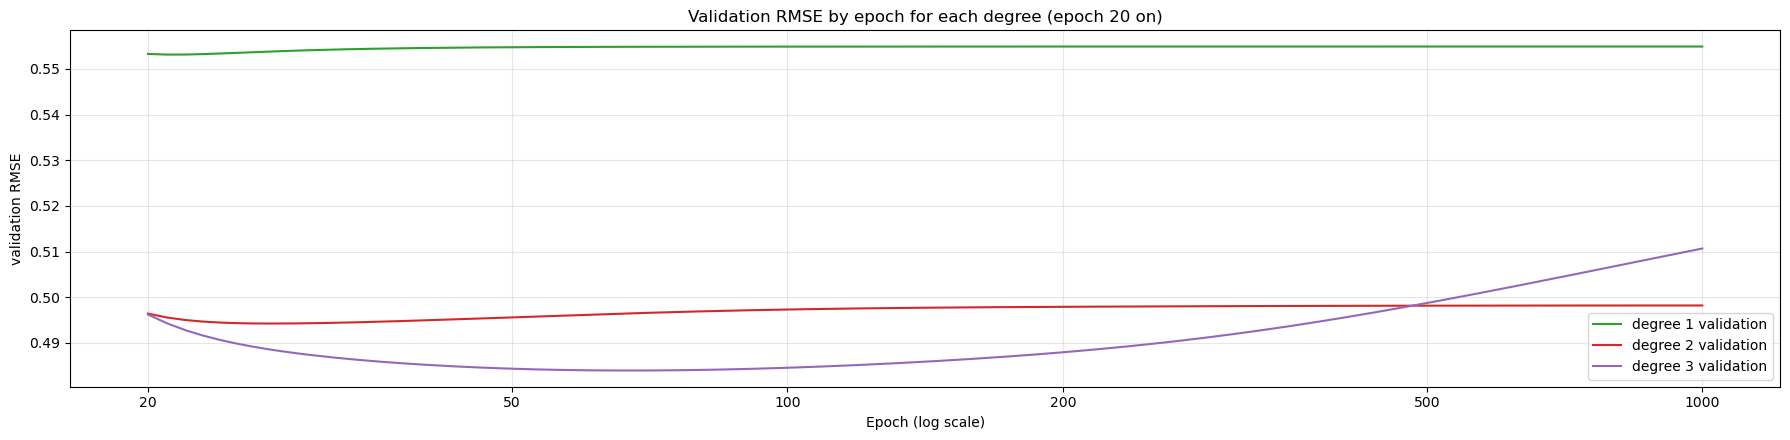

In [37]:
fig, ax = plt.subplots(figsize=(18, 4.5))

# the three validation lines on one chart
for (name, scores), color in zip(curve_scores.items(), ["C2", "C3", "C4"]):
	scores = scores.loc[CURVE_FIRST_EPOCH:]
	ax.plot(scores.index, scores["val RMSE"], color=color, label=f"{name} validation")
ax.set_xscale("log")
ax.set_xticks([20, 50, 100, 200, 500, 1000])
ax.set_xticklabels([20, 50, 100, 200, 500, 1000])
ax.minorticks_off()
ax.set_xlabel("Epoch (log scale)")
ax.set_ylabel("validation RMSE")
ax.set_title(f"Validation RMSE by epoch for each degree (epoch {CURVE_FIRST_EPOCH} on)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

**Loss by epoch and degree.** All three curves start at the same level (an RMSE of about 4.3 at epoch 1) and use the same rows, learning rate and seed, so the differences below come from the degree.

- **Degree 1 underfits.** Both lines go flat almost at once and stay high: training RMSE is 0.5382 and validation RMSE is 0.5549 from epoch 100 to epoch 1000. Its lowest validation RMSE (0.5531 at epoch 21) is higher than anything degree 2 or degree 3 reaches from epoch 20 on. More epochs change nothing.
- **Degree 2 is in between.** Training RMSE settles at 0.4886 and validation RMSE at 0.4982, both well below degree 1 and close to each other. Validation is lowest at epoch 27 (0.4942) and rises by 0.0040 before going flat, the same mild overfitting as in the selected model's curve above.
- **Degree 3 overfits.** Training RMSE falls for all 1000 epochs (0.4621 at epoch 20, 0.4315 at epoch 100, 0.4162 at epoch 1000). Validation RMSE is lowest at epoch 67 (0.4840) and climbs from there to 0.5107 at epoch 1000. The distance between the two lines grows from 0.0341 at epoch 20 to 0.0945 at epoch 1000.

Degree 3 is the best of the three if training stops early and worse than degree 2 if it does not. At its lowest point its validation RMSE (0.4840) is below degree 2's lowest (0.4942). By epoch 600 it is above degree 2 (0.5017 against 0.4982), and the last chart shows the two lines crossing just before epoch 500. This is one fold, but it explains the Degree Check: the degree 3 rows there scored well with a small learning rate and SGD's default stopping rule, which stops long before epoch 1000.

## Summary

**Does the model overfit or underfit?** It depends on the degree, the penalty and how long SGD trains. Validation loss shows the same two patterns in each view. When the model underfits, training and validation RMSE are both high and close together. When it overfits, training RMSE keeps improving while validation RMSE gets worse.

- **By degree** (closed form, 20 folds). Degree 1 underfits: training and validation RMSE are 0.5414 and 0.5458. Degree 2 lowers both (0.4860 and 0.5092) and is really better (-0.0365, SE 0.0080, all 20 folds). Degrees 3 and 4 overfit: training RMSE keeps falling (0.4096, then 0.2749) while validation RMSE rises (0.5284, then 1.1516).
- **By penalty** (SGD at degree 2, 20 folds). A stronger penalty moves the model toward underfitting. With Lasso, as alpha goes from 0.001 to 0.1, training RMSE rises from 0.4901 to 0.5469 and validation RMSE from 0.5074 to 0.5532, which is worse than degree 1. No penalty is a real improvement on plain SGD (0.5087), so at degree 2 there is little overfitting for a penalty to remove.
- **By epoch** (plain SGD, first fold). Degree 1 stays flat and high (0.5382 and 0.5549). Degree 2 settles with the two lines close together (0.4886 and 0.4982). Degree 3 overfits more with every epoch after 67: training RMSE falls to 0.4162 while validation RMSE rises from 0.4840 to 0.5107. A learning rate that is too small has the same effect as too few epochs: at eta0 0.0001 and degree 2, SGD stops at 0.6994 and 0.7073.

**The selected model** (degree 2, Lasso at alpha 0.001, eta0 0.01) does not underfit and overfits only mildly. Its cross-validated training and validation RMSE are 0.4901 and 0.5074, and on its own epoch curve validation ends 0.0030 above its lowest point. Degree 3 can score lower (0.5007), but not by more than the noise (-0.0067 against a ±0.0069 band), and only with a smaller learning rate and an early stop.

# Reproducibility
Every random step is seeded. The 20 folds come from `KFold` with the seeds in `SEEDS` (`Q1/consts.py`), and every `SGDRegressor` and the iterative imputer use `random_state=42`. Running the notebook again from the top gives the same numbers.